# Compact skew-t model -- paper figures (Figs 0-7)

Draft notebook. Reads `paper_figs_cache.h5`, produced by `gather_paper_data.py`
run on the cluster. Every fit performed *here* (rather than in the gather
script) is genuinely part of a figure's content -- e.g. Fig 1's b1,b2 fit,
Fig 2/4's sigma_v/Delta fits -- so you can re-run/tweak those without
re-touching the heavy data on spiffball.

**Not yet run against real data** -- I don't have access to your cluster, so
treat this as a checked-over-once first draft, not a validated result.

In [1]:
import numpy as np
import h5py as h5
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit, minimize
from scipy.interpolate import InterpolatedUnivariateSpline

import sys, os
sys.path.insert(0, os.path.expanduser('~/compact_streaming'))
from compact.model import skewed_t_pdf, sigma_mod, delta_mod, A_rho_mod, Pv_compact
from compact.lpt import GetLPTInputs

plt.rcParams.update({'text.usetex': True, 'font.family': 'Computer Modern Roman',
                      'axes.labelsize': 16})

CACHE = 'paper_figs_cache.h5'


In [2]:
from compact.velocities.pairhist import PairHist

FID_PAIRHIST_TMPL = ('/spiffball/cosweeney/simulations/AbacusSummit_base/halos/'
                      'AbacusSummit_base_{sim}/halos/{z}/data/pairhist_allbins.h5')
mass_bin = 3          # K_FIG0 -- lowest mass bin, decoupled from K_SINGLE (Figs 2/3/4/7)
sim = 'c000_ph000'    # must match FID_SIMS[0]
r_p_max = 60.0
r_los_max = 60.0

h = PairHist.load(FID_PAIRHIST_TMPL.format(sim=sim, z='z0.200'))
Rc = 0.5 * (h.R_edges[1:] + h.R_edges[:-1])
lc = 0.5 * (h.rlos_edges[1:] + h.rlos_edges[:-1])
R_mask = Rc < r_p_max
l_mask = lc < r_los_max

counts = h.counts[mass_bin][R_mask][:, l_mask].sum(axis=(0, 1))
v_centers = h.v_centers
n_pairs = int(h.n[mass_bin][R_mask][:, l_mask].sum())

## Fig 0 -- stacked P(v_los) in one mass bin, motivating nu

Raw (unstandardized) v_los,pec counts, summed over every (r_p, r_los) cell
in one mass bin, r_los > 0 only (true by construction of the accumulator's
grid). Fit a skew-t with **nu free** to see what the pooled distribution
actually prefers, vs. the nu=6 used everywhere else in the model.

free-nu fit:  nu = 11.765 +/- 0.053
nu=6 fixed fit: xi=102.56, omega=381.56, alpha=-0.48


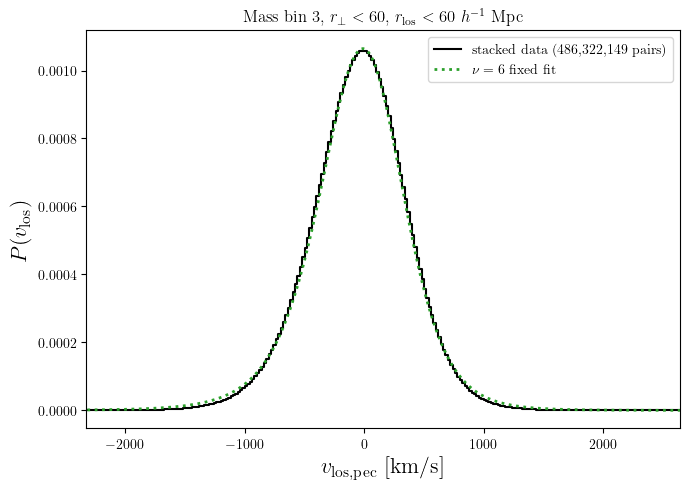

In [30]:
dv = v_centers[1] - v_centers[0]
density = counts / (counts.sum() * dv)

def skewed_t_free_nu(x, xi, omega, alpha, nu):
    return skewed_t_pdf(x, xi, omega, alpha, nu)

p0 = [np.average(v_centers, weights=counts), np.std(v_centers), -0.1, 6.0]
popt, pcov = curve_fit(skewed_t_free_nu, v_centers, density, p0=p0,
                        bounds=([-np.inf, 0, -50, 2.01], [np.inf, np.inf, 50, 100]),
                        maxfev=20_000)
perr = np.sqrt(np.diag(pcov))

def skewed_t_nu6(x, xi, omega, alpha):
    return skewed_t_pdf(x, xi, omega, alpha, 6)

popt6, pcov6 = curve_fit(skewed_t_nu6, v_centers, density, p0=p0[:3],
                          bounds=([-np.inf, 0, -50], [np.inf, np.inf, 50]),
                          maxfev=20_000)
perr6 = np.sqrt(np.diag(pcov6))

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(v_centers, density, drawstyle='steps-mid', color='k', label=f'stacked data ({n_pairs:,} pairs)')
# ax.plot(v_centers, skewed_t_free_nu(v_centers, *popt), 'C1--', lw=2,
#         label=rf'skew-t fit, $\nu={popt[3]:.2f}\pm{perr[3]:.2f}$')
ax.plot(v_centers, skewed_t_nu6(v_centers, *popt6), 'C2:', lw=2,
        label=r'$\nu=6$ fixed fit')
ax.set_xlim(popt[0] - 6*popt[1], popt[0] + 6*popt[1])
ax.set_xlabel(r'$v_{\rm los, pec}$ [km/s]')
ax.set_ylabel(r'$P(v_{\rm los})$')
ax.legend(fontsize=10)
ax.set_title(rf'Mass bin {mass_bin}, $r_\perp < {r_p_max:.0f}$, $r_{{\rm los}} < {r_los_max:.0f}\ h^{{-1}}$ Mpc')
fig.tight_layout()
print(f'free-nu fit:  nu = {popt[3]:.3f} +/- {perr[3]:.3f}')
print(f'nu=6 fixed fit: xi={popt6[0]:.2f}, omega={popt6[1]:.2f}, alpha={popt6[2]:.2f}')

## Fig 1 -- joint b1,b2 fit to xi_hh(r) and <v_r|r>, several mass bins

Adapted from `nb/model_validation/lpt_fits.ipynb`'s `joint_fit()`/`plot_joint_fits()`
(MDPL2, single bin) to AbacusSummit + several mass bins. b_s, b_3, and every
counterterm are fixed to zero -- only b1, b2 float, per your spec.

In [ ]:
# need to run with tpcf env (needs pycorr)
import importlib
import gather_paper_data as gpd
importlib.reload(gpd)

import h5py as h5
with h5.File(gpd.OUT_PATH, 'a') as out:
    gpd.run_fig1(out)

Fig 1: measuring xi_hh(r) per mass bin (the one new product)...


In [5]:
from scipy.optimize import curve_fit, minimize, differential_evolution

v_r: 5/10 phases done so far: ['c000_ph000', 'c000_ph001', 'c000_ph002', 'c000_ph003', 'c000_ph004']
xi_hh: cache has 16 phases (a separate, already-complete run)


/tmp/ipykernel_522622/2020527802.py:74: RuntimeWarning: Mean of empty slice
  vr_mean = np.nanmean(vr_stack, axis=0)
/tmp/ipykernel_522622/2020527802.py:77: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var_pp = np.nanvar(vr_stack, axis=0, ddof=1) / n_done


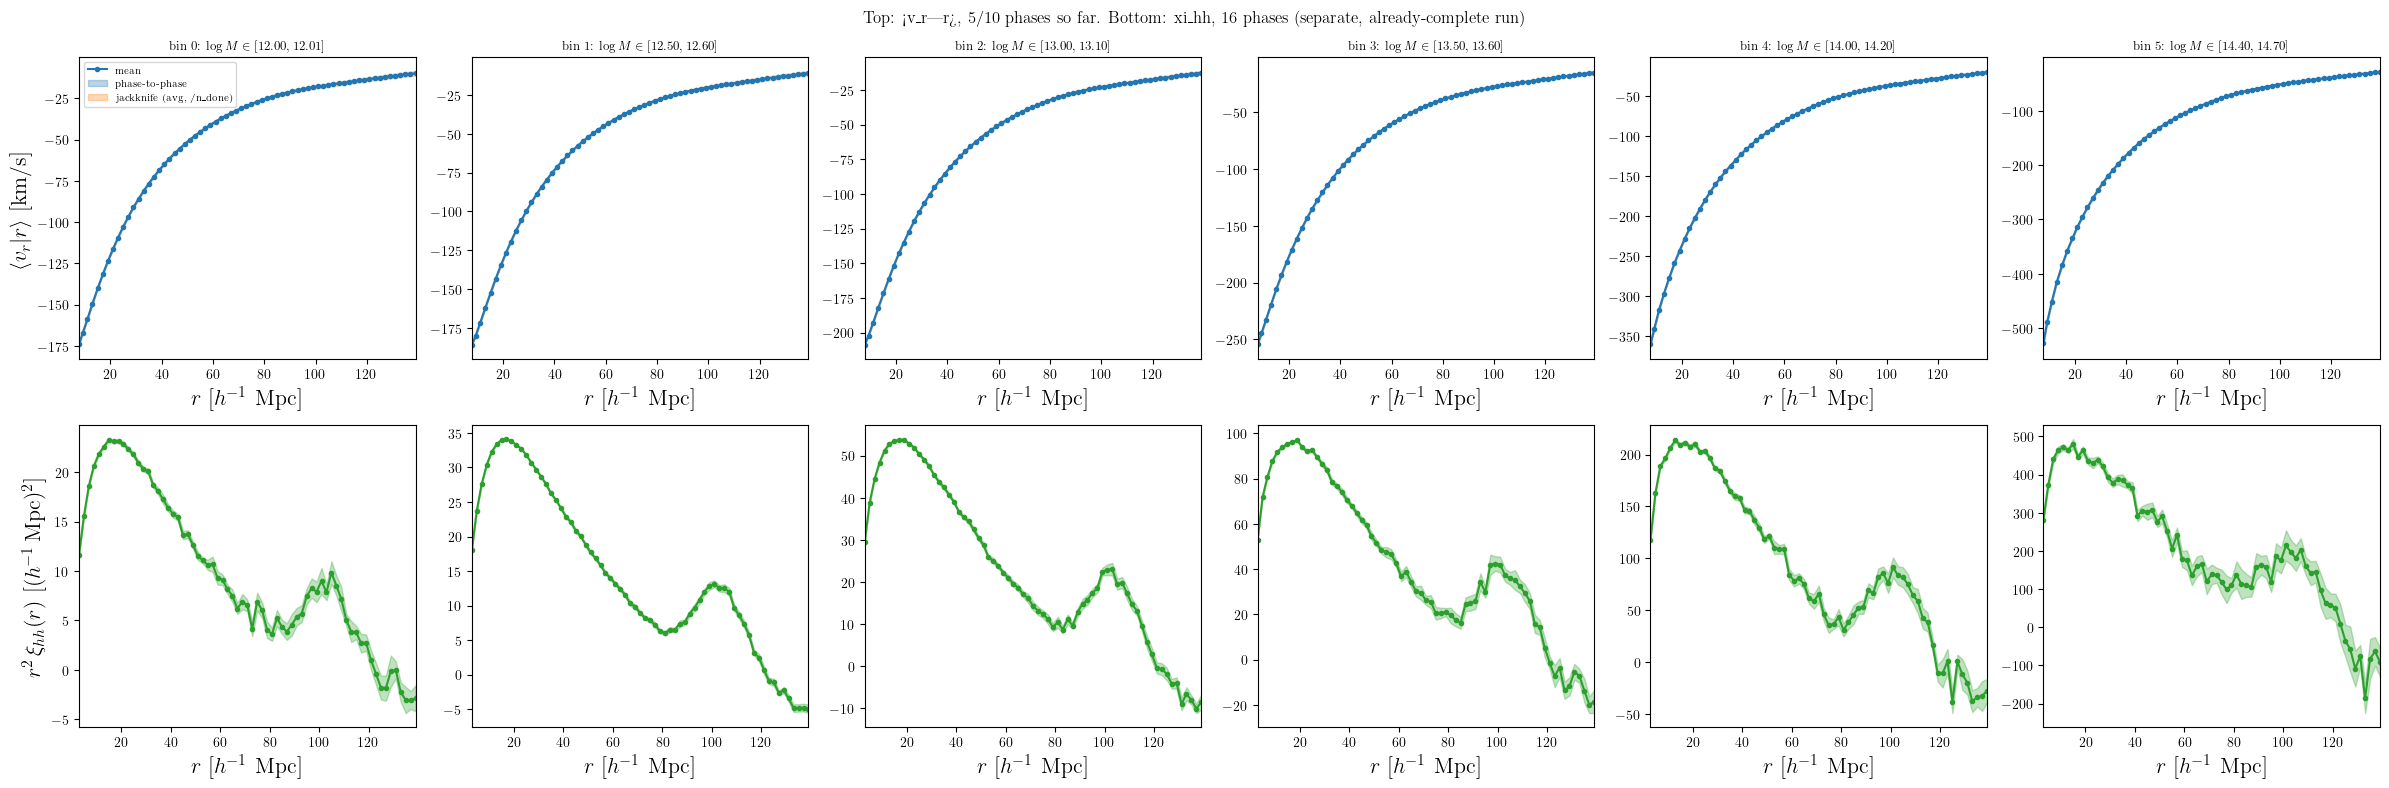

In [3]:
import os
from compact.velocities.pairhist import PairHist

def vr_profile(h, k, r_edges=None, r_max_trust=None):
    """Pair-weighted <v_r>(r) and sigma_vr(r) for mass bin k. From
    ASbase_compact_calibration.ipynb -- unchanged."""
    Rc = 0.5 * (h.R_edges[1:] + h.R_edges[:-1])
    lc = 0.5 * (h.rlos_edges[1:] + h.rlos_edges[:-1])
    r3 = np.sqrt(Rc[:, None] ** 2 + lc[None, :] ** 2).ravel()
    n = h.n[k].ravel().astype(float)
    s1 = h.sum_vr[k].ravel()
    s2 = h.sum_vr2[k].ravel()
    if r_edges is None:
        top = r_max_trust if r_max_trust is not None else h.R_edges[-1]
        r_edges = np.arange(0.0, top + 2.0, 2.0)
    nb_bins = len(r_edges) - 1
    idx = np.searchsorted(r_edges, r3, side='right') - 1
    ok = (idx >= 0) & (idx < nb_bins) & (n > 0)

    def acc(w):
        return np.bincount(idx[ok], weights=w[ok], minlength=nb_bins)

    N = acc(n)
    r_eff = np.where(N > 0, acc(n * r3) / np.where(N > 0, N, 1), np.nan)
    mu = np.where(N > 0, acc(s1) / np.where(N > 0, N, 1), np.nan)
    m2 = np.where(N > 0, acc(s2) / np.where(N > 0, N, 1), np.nan)
    sd = np.sqrt(np.maximum(m2 - mu ** 2, 0.0))
    return r_eff, mu, sd, N.astype(np.int64)

JK_OUT_TMPL = ('/spiffball/cosweeney/simulations/AbacusSummit_base/halos/'
               'AbacusSummit_base_{sim}/halos/z0.200/data/pairhist_allbins_jk.h5')
ALL_PLANNED_PHASES = [f'c000_ph{i:03d}' for i in range(0, 10)]   # the planned 10
VR_R_EDGES = np.arange(2.0, 142.0, 2.0)
N_MASS = 6
LOG_MASS_EDGES = np.array([[12, 12.01], [12.5, 12.6], [13, 13.1],
                            [13.5, 13.6], [14.0, 14.2], [14.4, 14.7]])

done_phases = [s for s in ALL_PLANNED_PHASES if os.path.exists(JK_OUT_TMPL.format(sim=s))]
n_done = len(done_phases)
print(f'v_r: {n_done}/{len(ALL_PLANNED_PHASES)} phases done so far: {done_phases}')

vr_by_bin = {k: [] for k in range(N_MASS)}
vr_jk_cov_by_bin = {k: [] for k in range(N_MASS)}
r_vr_ref = None

for sim in done_phases:
    path = JK_OUT_TMPL.format(sim=sim)
    total = PairHist.load(path)
    with h5.File(path, 'r') as hdf:
        for k in range(N_MASS):
            r_eff, mean_vr, sd_vr, npairs = vr_profile(total, k, r_edges=VR_R_EDGES)
            vr_by_bin[k].append(mean_vr)
            if r_vr_ref is None:
                r_vr_ref = r_eff
            vr_jk_cov_by_bin[k].append(hdf[f'vr_jk_cov_mbin{k}'][()])

# xi_hh from the EXISTING cache -- a separate, already-computed pipeline,
# almost certainly at a DIFFERENT (probably larger) phase count than v_r's
# partial total above.
with h5.File(CACHE, 'r') as hdf:
    g1 = hdf['fig1']
    xi_n_phases = g1['mbin_0'].attrs['n_phases']
    print(f'xi_hh: cache has {xi_n_phases} phases (a separate, already-complete run)')
    r_xi_by_bin, xi_by_bin, xi_err_by_bin = {}, {}, {}
    for k in range(N_MASS):
        gk = g1[f'mbin_{k}']
        r_xi_by_bin[k] = gk['r_cens'][()]
        xi_by_bin[k] = gk['xi'][()]
        xi_err_by_bin[k] = np.sqrt(np.diag(gk['cov'][()]))

fig, axes = plt.subplots(2, 6, figsize=(24, 8))
for k in range(N_MASS):
    vr_stack = np.array(vr_by_bin[k])            # (n_done, n_r)
    vr_mean = np.nanmean(vr_stack, axis=0)

    # error 1: phase-to-phase scatter across whatever phases are done so far
    var_pp = np.nanvar(vr_stack, axis=0, ddof=1) / n_done

    # error 2: each phase's own within-box jackknife covariance, averaged
    # across the same done phases and divided by n_done -- same "average
    # then scale by n_phases" logic already used for xi_hh's cov_jk earlier
    # in this notebook.
    cov_jk_mean = np.array(vr_jk_cov_by_bin[k]).mean(axis=0) / n_done
    var_jk = np.diag(cov_jk_mean)

    ax_ = axes[0, k]
    ax_.plot(r_vr_ref, vr_mean, 'o-', ms=3, c='C0', zorder=2, label='mean')
    ax_.fill_between(r_vr_ref, vr_mean - np.sqrt(var_pp), vr_mean + np.sqrt(var_pp),
                      color='C0', alpha=0.3, zorder=1, label='phase-to-phase')
    ax_.fill_between(r_vr_ref, vr_mean - np.sqrt(var_jk), vr_mean + np.sqrt(var_jk),
                      color='C1', alpha=0.3, zorder=1, label='jackknife (avg, /n_done)')
    lo, hi = LOG_MASS_EDGES[k]
    ax_.set_title(rf'bin {k}: $\log M \in [{lo:.2f},{hi:.2f}]$', fontsize=9)
    ax_.set_xlabel(r'$r$ [$h^{-1}$ Mpc]')
    ax_.margins(x=0)
    if k == 0:
        ax_.set_ylabel(r'$\langle v_r|r\rangle$ [km/s]')
        ax_.legend(fontsize=7)

    ax_xi = axes[1, k]
    r_xi, xihh, xi_err = r_xi_by_bin[k], xi_by_bin[k], xi_err_by_bin[k]
    xi_r2 = r_xi**2 * xihh
    ax_xi.plot(r_xi, xi_r2, 'o-', ms=3, c='C2', zorder=2)
    ax_xi.fill_between(r_xi, r_xi**2*(xihh - xi_err), r_xi**2*(xihh + xi_err),
                        color='C2', alpha=0.3, zorder=1)
    ax_xi.set_xlabel(r'$r$ [$h^{-1}$ Mpc]')
    ax_xi.margins(x=0)
    if k == 0:
        ax_xi.set_ylabel(r'$r^2\,\xi_{hh}(r)$ [$(h^{-1}\,{\rm Mpc})^2$]')

fig.suptitle(f'Top: <v_r|r>, {n_done}/{len(ALL_PLANNED_PHASES)} phases so far. '
             f'Bottom: xi_hh, {xi_n_phases} phases (separate, already-complete run)')
fig.tight_layout()

xi_hh: 16 phases (cached, phase-to-phase). v_r: c000_ph000 alone (within-box jackknife). Diagonal-only.
bin 0: success=True, nfev=912, chi2=332.230, dof=118, reduced_chi2=2.816, b1=-0.088, b2=1.341


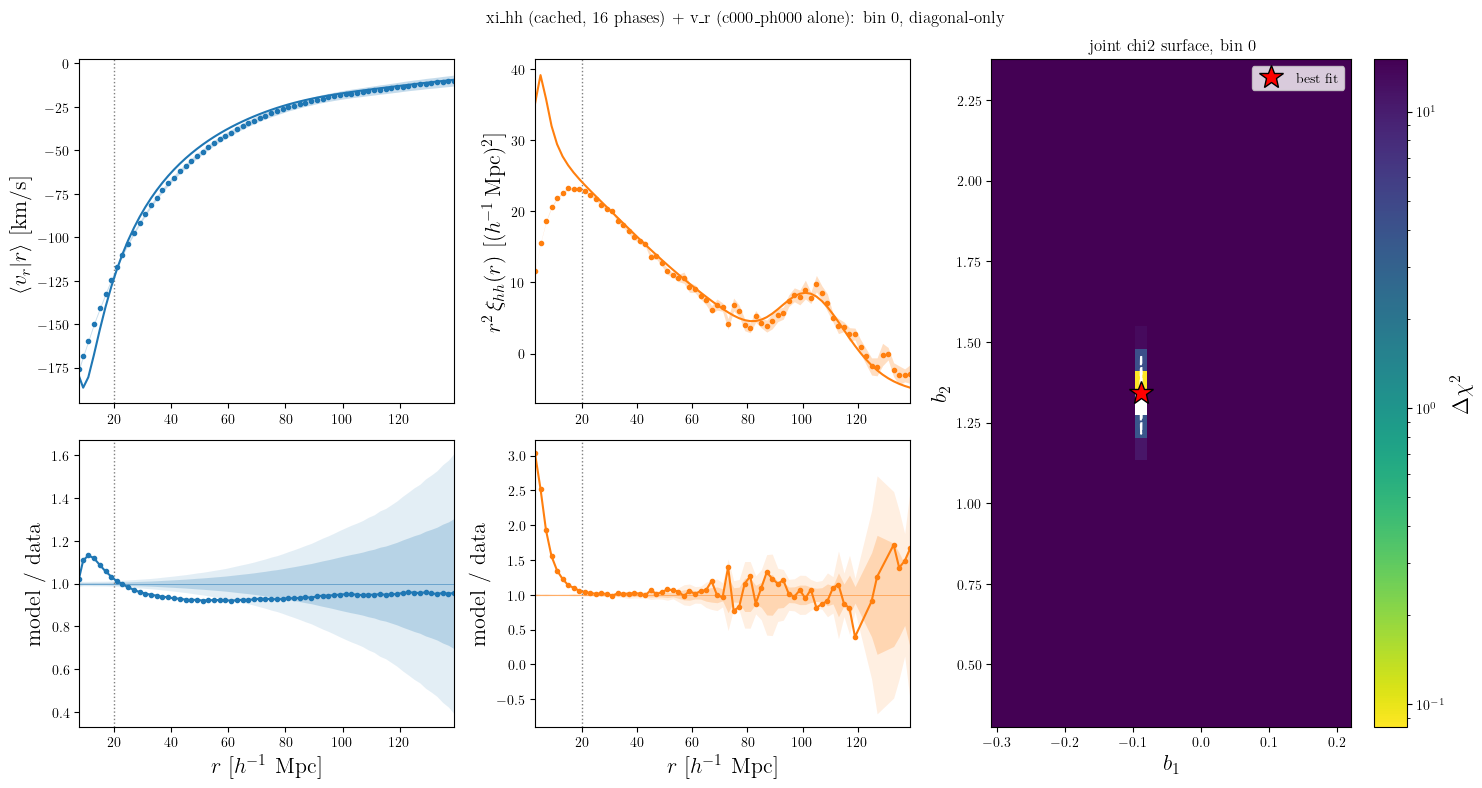

In [12]:
FID_COSMO = [0.6736, 0.02237, 0.1200, 2.083e-9, 0.9649]
FID_REDSHIFT = 0.2
R_MIN_FIT = 20.0

lpt = GetLPTInputs(redshift=FID_REDSHIFT, cosmo=FID_COSMO)
lpt.get_pklin_gsm()

def model_xihh(r, b1, b2, bs=0.0):
    pars = np.array([b1, b2, bs, 0, 0, 0, 0, 0, 0])
    return lpt.xi_real(r, pars)

def model_vr(r, b1, b2, bs=0.0):
    pars = np.array([b1, b2, bs, 0, 0, 0, 0, 0, 0])
    lpt._ensure_cumulants(pars)
    v_int = np.interp(r, lpt.gsm.rint, lpt.gsm.veft)
    xi_consistent = lpt.gsm.compute_xi_real(r, *pars)
    return lpt.conv * lpt.f * v_int / (1 + xi_consistent)


def fit_bias(r_min=15.0, fit_bs=False, mode='joint',
             r_xi=None, xihh=None, var_xi=None,
             r_vr=None, vr=None, var_vr=None,
             popsize=15, maxiter=150, tol=1e-6, seed=0):
    # diagonal-only: var_xi/var_vr are 1D variance arrays (np.diag of the
    # full covariance), not the full matrix -- no regularized_pinv needed.
    if mode in ('joint', 'xi'):
        m_xi = r_xi > r_min
        r_xi_fit, xihh_fit, var_xi_fit = r_xi[m_xi], xihh[m_xi], var_xi[m_xi]
    if mode in ('joint', 'vr'):
        m_vr = r_vr > r_min
        r_vr_fit, vr_fit, var_vr_fit = r_vr[m_vr], vr[m_vr], var_vr[m_vr]

    def loss(params):
        b1, b2 = params[0], params[1]
        bs = params[2] if fit_bs else 0.0
        c = 0.0
        if mode in ('joint', 'xi'):
            res = model_xihh(r_xi_fit, b1, b2, bs) - xihh_fit
            c += np.sum(res**2 / var_xi_fit)
        if mode in ('joint', 'vr'):
            res = model_vr(r_vr_fit, b1, b2, bs) - vr_fit
            c += np.sum(res**2 / var_vr_fit)
        return c if np.isfinite(c) else np.inf

    bounds = [(-0.3, 5.0), (-10.0, 10.0)] + ([(-5.0, 5.0)] if fit_bs else [])
    result = differential_evolution(loss, bounds, tol=tol, seed=seed,
                                     maxiter=maxiter, popsize=popsize, polish=True)

    n_data = 0
    if mode in ('joint', 'xi'):
        n_data += len(xihh_fit)
    if mode in ('joint', 'vr'):
        n_data += len(vr_fit)
    result.dof = max(n_data - len(bounds), 1)
    result.chi2 = result.fun
    result.reduced_chi2 = result.fun / result.dof
    return result


def chi2_grid(mode, b1_grid, b2_grid, r_min=15.0,
              r_xi=None, xihh=None, var_xi=None, r_vr=None, vr=None, var_vr=None):
    if mode in ('joint', 'xi'):
        m_xi = r_xi > r_min
        r_xi_fit, xihh_fit, var_xi_fit = r_xi[m_xi], xihh[m_xi], var_xi[m_xi]
    if mode in ('joint', 'vr'):
        m_vr = r_vr > r_min
        r_vr_fit, vr_fit, var_vr_fit = r_vr[m_vr], vr[m_vr], var_vr[m_vr]

    chi2 = np.zeros((len(b1_grid), len(b2_grid)))
    for i, b1 in enumerate(b1_grid):
        for j, b2 in enumerate(b2_grid):
            c = 0.0
            if mode in ('joint', 'xi'):
                res = model_xihh(r_xi_fit, b1, b2) - xihh_fit
                c += np.sum(res**2 / var_xi_fit)
            if mode in ('joint', 'vr'):
                res = model_vr(r_vr_fit, b1, b2) - vr_fit
                c += np.sum(res**2 / var_vr_fit)
            chi2[i, j] = c
    return chi2


# ---- xi_hh: ALREADY-cached, phase-averaged -- no recompute, no pycorr ----
SIM = 'c000_ph000'
K_BIN = 0

with h5.File(CACHE, 'r') as hdf:
    gk = hdf['fig1'][f'mbin_{K_BIN}']
    r_xi = gk['r_cens'][()]
    xihh = gk['xi'][()]
    var_xi = np.diag(gk['cov'][()])
    xi_n_phases = gk.attrs['n_phases']

# ---- v_r: single phase, within-box jackknife -- also no pycorr ----
from compact.velocities.pairhist import PairHist

r_edges_shared = np.arange(2.0, 142.0, 2.0)
JK_PATH = ('/spiffball/cosweeney/simulations/AbacusSummit_base/halos/'
           f'AbacusSummit_base_{SIM}/halos/z0.200/data/pairhist_allbins_jk.h5')
total = PairHist.load(JK_PATH)
r_vr, vr, sd_vr, npairs = vr_profile(total, K_BIN, r_edges=r_edges_shared)
with h5.File(JK_PATH, 'r') as hdf:
    var_vr = np.diag(hdf[f'vr_jk_cov_mbin{K_BIN}'][()])

good = np.isfinite(vr) & (npairs > 1000) & (var_vr > 0)
r_vr, vr, var_vr = r_vr[good], vr[good], var_vr[good]

print(f'xi_hh: {xi_n_phases} phases (cached, phase-to-phase). v_r: {SIM} alone (within-box jackknife). Diagonal-only.')

res = fit_bias(mode='joint', r_min=R_MIN_FIT, r_xi=r_xi, xihh=xihh, var_xi=var_xi,
               r_vr=r_vr, vr=vr, var_vr=var_vr)
b1, b2 = res.x
print(f'bin {K_BIN}: success={res.success}, nfev={res.nfev}, chi2={res.chi2:.3f}, '
      f'dof={res.dof}, reduced_chi2={res.reduced_chi2:.3f}, b1={b1:.3f}, b2={b2:.3f}')

xi_model = model_xihh(r_xi, b1, b2)
vr_model = model_vr(r_vr, b1, b2)
xi_r2, xi_model_r2 = r_xi**2 * xihh, r_xi**2 * xi_model
vr_err, xi_err = np.sqrt(var_vr), np.sqrt(var_xi)

fig = plt.figure(figsize=(15, 8))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 1.2], height_ratios=[1.2, 1])
ax_vr, ax_vr_r = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[1, 0])
ax_xi, ax_xi_r = fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 1])
ax_like = fig.add_subplot(gs[:, 2])

ax_vr.plot(r_vr, vr, 'o', ms=3, c='C0', zorder=2)
ax_vr.fill_between(r_vr, vr - vr_err, vr + vr_err, color='C0', alpha=0.25, lw=0, zorder=1)
ax_vr.plot(r_vr, vr_model, '-', c='C0')
ax_vr.set_ylabel(r'$\langle v_r|r\rangle$ [km/s]')

ax_xi.plot(r_xi, xi_r2, 'o', ms=3, c='C1', zorder=2)
ax_xi.fill_between(r_xi, xi_r2 - r_xi**2*xi_err, xi_r2 + r_xi**2*xi_err, color='C1', alpha=0.25, lw=0, zorder=1)
ax_xi.plot(r_xi, xi_model_r2, '-', c='C1')
ax_xi.set_ylabel(r'$r^2\,\xi_{hh}(r)$ [$(h^{-1}\,{\rm Mpc})^2$]')

vr_ratio = vr_model / vr
vr_ratio_err = np.abs(vr_ratio) * (vr_err / np.abs(vr))
ax_vr_r.axhline(1, c='C0', lw=0.7, alpha=0.5, zorder=0)
ax_vr_r.fill_between(r_vr, 1 - 2*vr_ratio_err, 1 + 2*vr_ratio_err, color='C0', alpha=0.12, lw=0, zorder=0)
ax_vr_r.fill_between(r_vr, 1 - vr_ratio_err, 1 + vr_ratio_err, color='C0', alpha=0.22, lw=0, zorder=0)
ax_vr_r.plot(r_vr, vr_ratio, 'o-', ms=3, c='C0', zorder=2)
ax_vr_r.set_ylabel('model / data')
ax_vr_r.set_xlabel(r'$r$ [$h^{-1}$ Mpc]')

xi_ratio = xi_model / xihh
xi_ratio_err = np.abs(xi_ratio) * (xi_err / np.abs(xihh))
xi_good = np.abs(xihh) > xi_err
ax_xi_r.axhline(1, c='C1', lw=0.7, alpha=0.5, zorder=0)
ax_xi_r.fill_between(r_xi[xi_good], 1 - 2*xi_ratio_err[xi_good], 1 + 2*xi_ratio_err[xi_good],
                      color='C1', alpha=0.12, lw=0, zorder=0)
ax_xi_r.fill_between(r_xi[xi_good], 1 - xi_ratio_err[xi_good], 1 + xi_ratio_err[xi_good],
                      color='C1', alpha=0.22, lw=0, zorder=0)
ax_xi_r.plot(r_xi[xi_good], xi_ratio[xi_good], 'o-', ms=3, c='C1', zorder=2)
ax_xi_r.set_ylabel('model / data')
ax_xi_r.set_xlabel(r'$r$ [$h^{-1}$ Mpc]')

for ax_ in (ax_vr, ax_vr_r, ax_xi, ax_xi_r):
    ax_.axvline(R_MIN_FIT, color='gray', ls=':', lw=1, zorder=0)
    ax_.margins(x=0)

b1_grid = np.linspace(max(-0.3, b1 - 0.3), b1 + 0.3, 30)
b2_grid = np.linspace(b2 - 1.0, b2 + 1.0, 30)
chi2_2d = chi2_grid('joint', b1_grid, b2_grid, r_min=R_MIN_FIT,
                     r_xi=r_xi, xihh=xihh, var_xi=var_xi, r_vr=r_vr, vr=vr, var_vr=var_vr)
dchi2_2d = chi2_2d - chi2_2d.min()
B1, B2 = np.meshgrid(b1_grid, b2_grid, indexing='ij')

im = ax_like.pcolormesh(B1, B2, dchi2_2d, shading='auto', cmap='viridis_r', vmax=15, norm='log')
fig.colorbar(im, ax=ax_like, label=r'$\Delta\chi^2$')
ax_like.contour(B1, B2, dchi2_2d, levels=[2.3, 6.18], colors='white', linestyles=['-', '--'])
ax_like.plot(b1, b2, '*', c='red', ms=18, mec='k', label='best fit')
ax_like.set_xlabel(r'$b_1$')
ax_like.set_ylabel(r'$b_2$')
ax_like.set_title(f'joint chi2 surface, bin {K_BIN}')
ax_like.legend()

fig.suptitle(f'xi_hh (cached, {xi_n_phases} phases) + v_r ({SIM} alone): bin {K_BIN}, diagonal-only')
fig.tight_layout()

/home/cosweeney/miniconda3/envs/scienv/lib/python3.12/site-packages/velocileptors/LPT/cleft_fftw.py:125: RuntimeWarning: overflow encountered in exp
  expon = np.exp(-0.5*ksq * (self.XYlin - self.sigma))
/home/cosweeney/miniconda3/envs/scienv/lib/python3.12/site-packages/velocileptors/LPT/cleft_fftw.py:126: RuntimeWarning: overflow encountered in expm1
  exponm1 = np.expm1(-0.5*ksq * (self.XYlin - self.sigma))
/home/cosweeney/miniconda3/envs/scienv/lib/python3.12/site-packages/velocileptors/LPT/cleft_fftw.py:162: RuntimeWarning: overflow encountered in multiply
  bias_integrands = bias_integrands * expon
/home/cosweeney/miniconda3/envs/scienv/lib/python3.12/site-packages/velocileptors/LPT/cleft_fftw.py:162: RuntimeWarning: invalid value encountered in multiply
  bias_integrands = bias_integrands * expon
/home/cosweeney/miniconda3/envs/scienv/lib/python3.12/site-packages/velocileptors/Utils/spherical_bessel_transform_fftw.py:99: RuntimeWarning: overflow encountered in multiply
  self.fs

bin 0 [xi alone]: b1=0.000, b2=0.751, reduced_chi2=29.882
bin 0 [vr alone]: b1=0.000, b2=-0.055, reduced_chi2=6.966
bin 0 [2-param]: success=True, nfev=1614, chi2=2754.592, dof=123, reduced_chi2=22.395, b1=0.000, b2=-0.039
bin 0 [3-param]: success=True, nfev=3305, chi2=2717.400, dof=122, reduced_chi2=22.274, b1=0.000, b2=-0.006, bs=0.095, delta_chi2=37.192
  -> bin 0: using 3-param fit (b_s significant at ~95% CL)
bin 1 [xi alone]: b1=0.060, b2=-0.631, reduced_chi2=0.148
bin 1 [vr alone]: b1=0.071, b2=-0.023, reduced_chi2=7.166
bin 1 [2-param]: success=True, nfev=1005, chi2=685.222, dof=123, reduced_chi2=5.571, b1=0.079, b2=-0.058
bin 1 [3-param]: success=True, nfev=2716, chi2=432.954, dof=122, reduced_chi2=3.549, b1=0.075, b2=0.150, bs=0.416, delta_chi2=252.268
  -> bin 1: using 3-param fit (b_s significant at ~95% CL)
bin 2 [xi alone]: b1=0.356, b2=-0.404, reduced_chi2=0.134
bin 2 [vr alone]: b1=0.218, b2=-0.026, reduced_chi2=3.823
bin 2 [2-param]: success=True, nfev=1149, chi2=4455.

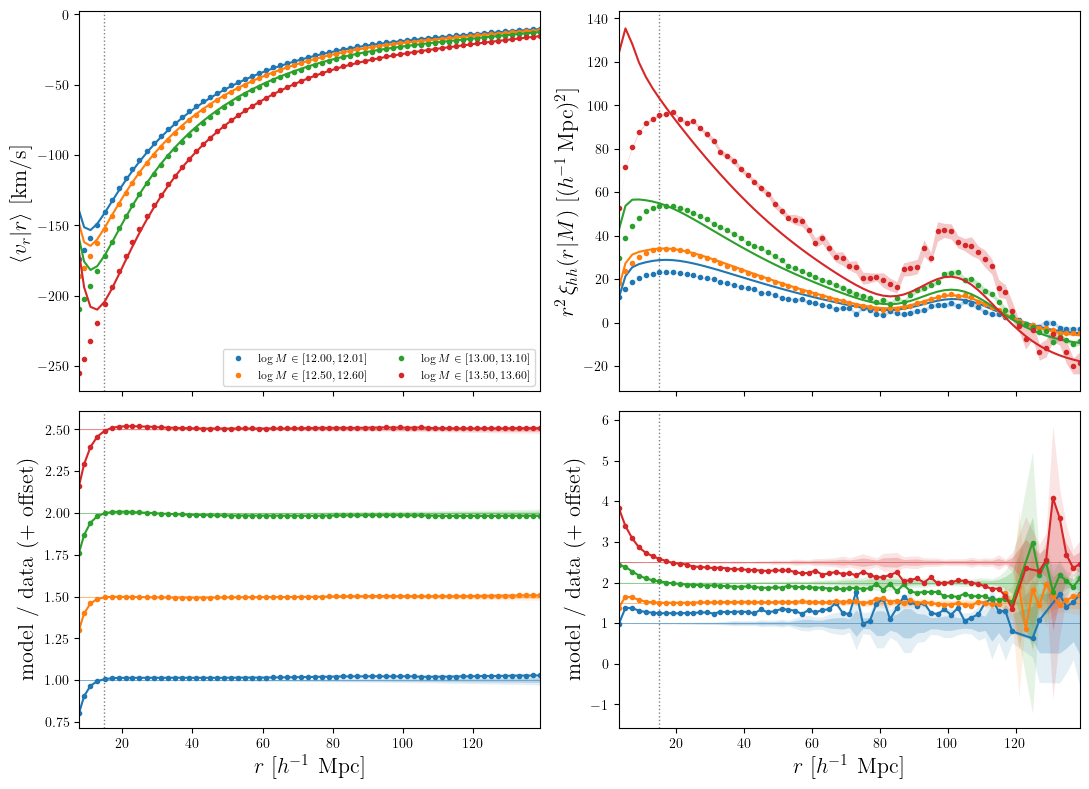

In [3]:
 FID_COSMO = [0.6736, 0.02237, 0.1200, 2.083e-9, 0.9649]   # h, ombh2, omch2, As, ns --
                                                            # official AbacusSummit c000 (arXiv:2110.11413)
FID_REDSHIFT = 0.2

lpt = GetLPTInputs(redshift=FID_REDSHIFT, cosmo=FID_COSMO)
lpt.get_pklin_gsm()

def model_xihh(r, b1, b2, bs=0.0):
    pars = np.array([b1, b2, bs, 0, 0, 0, 0, 0, 0])
    return lpt.xi_real(r, pars)

def model_vr(r, b1, b2, bs=0.0):
    pars = np.array([b1, b2, bs, 0, 0, 0, 0, 0, 0])
    lpt._ensure_cumulants(pars)
    v_int = np.interp(r, lpt.gsm.rint, lpt.gsm.veft)
    xi_consistent = lpt.gsm.compute_xi_real(r, *pars)
    return lpt.conv * lpt.f * v_int / (1 + xi_consistent)


def fit_bias(r_min=15.0, fit_bs=False, mode='joint',
             r_xi=None, xihh=None, cov_xi=None,
             r_vr=None, vr=None, cov_vr=None,
             max_rank=None, popsize=15, maxiter=150, tol=1e-6, seed=0):
    if mode in ('joint', 'xi'):
        m_xi = r_xi > r_min
        r_xi_fit, xihh_fit = r_xi[m_xi], xihh[m_xi]
        cov_xi_fit = cov_xi[np.ix_(m_xi, m_xi)]
        rank_xi = max_rank or max(1, m_xi.sum())
        inv_cov_xi = regularized_pinv(cov_xi_fit, rank_xi)
    if mode in ('joint', 'vr'):
        m_vr = r_vr > r_min
        r_vr_fit, vr_fit = r_vr[m_vr], vr[m_vr]
        cov_vr_fit = cov_vr[np.ix_(m_vr, m_vr)]
        rank_vr = max_rank or max(1, m_vr.sum())
        inv_cov_vr = regularized_pinv(cov_vr_fit, rank_vr)

    def loss(params):
        b1, b2 = params[0], params[1]
        bs = params[2] if fit_bs else 0.0
        c = 0.0
        if mode in ('joint', 'xi'):
            res = model_xihh(r_xi_fit, b1, b2, bs) - xihh_fit
            c += res @ inv_cov_xi @ res
        if mode in ('joint', 'vr'):
            res = model_vr(r_vr_fit, b1, b2, bs) - vr_fit
            c += res @ inv_cov_vr @ res
        return c

    bounds = [(0.0, 5.0), (-10.0, 10.0)] + ([(-5.0, 5.0)] if fit_bs else [])
    result = differential_evolution(loss, bounds, tol=tol, seed=seed,
                                     maxiter=maxiter, popsize=popsize, polish=True)

    n_data = 0
    if mode in ('joint', 'xi'):
        n_data += len(xihh_fit)
    if mode in ('joint', 'vr'):
        n_data += len(vr_fit)
    result.dof = max(n_data - len(bounds), 1)
    result.chi2 = result.fun
    result.reduced_chi2 = result.fun / result.dof
    return result


def regularized_pinv(cov, max_rank):
    vals, vecs = np.linalg.eigh(cov)
    order = np.argsort(vals)[::-1]
    vals, vecs = vals[order], vecs[:, order]
    max_rank = min(max_rank, len(vals))
    vals = np.clip(vals[:max_rank], 1e-300, None)
    vecs = vecs[:, :max_rank]
    return vecs @ np.diag(1.0 / vals) @ vecs.T


with h5.File(CACHE, 'r') as hdf:
    g1 = hdf['fig1']
    mass_bins_available = sorted(int(k.split('_')[1]) for k in g1.keys())
    mass_bins_available = mass_bins_available[:-2]

    LOG_MASS_EDGES = np.array([[12, 12.01], [12.5, 12.6], [13, 13.1],
                                [13.5, 13.6], [14.0, 14.2], [14.4, 14.7]])

    fig, ax = plt.subplots(2, 2, figsize=(11, 8), sharex='col',
                            gridspec_kw={'height_ratios': [1.2, 1]})
    offset_step = 0.5
    R_MIN_FIT = 15.0
    DELTA_CHI2_THRESHOLD = 4.0

    def plot_ratio_bands(ax_, r, baseline, err, color):
        ax_.axhline(baseline, c=color, lw=0.7, alpha=0.5, zorder=0)
        ax_.fill_between(r, baseline - 2*err, baseline + 2*err, color=color, alpha=0.12, lw=0, zorder=0)
        ax_.fill_between(r, baseline - err, baseline + err, color=color, alpha=0.22, lw=0, zorder=0)

    for n, k in enumerate(mass_bins_available):
        gk = g1[f'mbin_{k}']
        r_xi, xihh, cov_xi = gk['r_cens'][()], gk['xi'][()], gk['cov'][()]
        r_vr, vr, cov_vr = gk['vr_r'][()], gk['vr_mean'][()], gk['vr_cov'][()]
        vr_n = gk['vr_npairs'][()]
        good = np.isfinite(vr) & (vr_n > 1000) & (np.diag(cov_vr) > 0)
        r_vr, vr = r_vr[good], vr[good]
        cov_vr = cov_vr[np.ix_(good, good)]
        n_phases = gk.attrs['n_phases']
        max_rank = max(1, n_phases - 2)

        res_xi_single = fit_bias(mode='xi', r_min=R_MIN_FIT, r_xi=r_xi, xihh=xihh, cov_xi=cov_xi,
                                 max_rank=max_rank)
        res_vr_single = fit_bias(mode='vr', r_min=R_MIN_FIT, r_vr=r_vr, vr=vr, cov_vr=cov_vr,
                                 max_rank=max_rank)
        print(f'bin {k} [xi alone]: b1={res_xi_single.x[0]:.3f}, b2={res_xi_single.x[1]:.3f}, '
              f'reduced_chi2={res_xi_single.reduced_chi2:.3f}')
        print(f'bin {k} [vr alone]: b1={res_vr_single.x[0]:.3f}, b2={res_vr_single.x[1]:.3f}, '
              f'reduced_chi2={res_vr_single.reduced_chi2:.3f}')

        res2 = fit_bias(mode='joint', r_min=R_MIN_FIT, r_xi=r_xi, xihh=xihh, cov_xi=cov_xi,
                        r_vr=r_vr, vr=vr, cov_vr=cov_vr, max_rank=max_rank)
        b1, b2 = res2.x
        bs = 0.0
        print(f'bin {k} [2-param]: success={res2.success}, nfev={res2.nfev}, chi2={res2.chi2:.3f}, '
              f'dof={res2.dof}, reduced_chi2={res2.reduced_chi2:.3f}, b1={b1:.3f}, b2={b2:.3f}')

        res3 = fit_bias(mode='joint', r_min=R_MIN_FIT, fit_bs=True, r_xi=r_xi, xihh=xihh, cov_xi=cov_xi,
                        r_vr=r_vr, vr=vr, cov_vr=cov_vr, max_rank=max_rank)
        b1_3, b2_3, bs_3 = res3.x
        delta_chi2 = res2.chi2 - res3.chi2
        print(f'bin {k} [3-param]: success={res3.success}, nfev={res3.nfev}, chi2={res3.chi2:.3f}, '
              f'dof={res3.dof}, reduced_chi2={res3.reduced_chi2:.3f}, '
              f'b1={b1_3:.3f}, b2={b2_3:.3f}, bs={bs_3:.3f}, delta_chi2={delta_chi2:.3f}')

        if delta_chi2 > DELTA_CHI2_THRESHOLD:
            b1, b2, bs = b1_3, b2_3, bs_3
            print(f'  -> bin {k}: using 3-param fit (b_s significant at ~95% CL)')
        else:
            print(f'  -> bin {k}: using 2-param fit (b_s not significant)')

        xi_model = model_xihh(r_xi, b1, b2, bs)
        vr_model = model_vr(r_vr, b1, b2, bs)

        xi_r2 = r_xi**2 * xihh
        xi_model_r2 = r_xi**2 * xi_model
        vr_err = np.sqrt(np.diag(cov_vr))
        xi_err = np.sqrt(np.diag(cov_xi))

        lo, hi = LOG_MASS_EDGES[k]
        ax[0, 0].plot(r_vr, vr, 'o', ms=3, c=f'C{n}', zorder=2,
                       label=rf'$\log M \in [{lo:.2f}, {hi:.2f}]$')
        ax[0, 0].fill_between(r_vr, vr - vr_err, vr + vr_err,
                               color=f'C{n}', alpha=0.25, lw=0, zorder=1)
        ax[0, 0].plot(r_vr, vr_model, '-', c=f'C{n}')

        ax[0, 1].plot(r_xi, xi_r2, 'o', ms=3, c=f'C{n}', zorder=2)
        ax[0, 1].fill_between(r_xi, xi_r2 - r_xi**2*xi_err, xi_r2 + r_xi**2*xi_err,
                               color=f'C{n}', alpha=0.25, lw=0, zorder=1)
        ax[0, 1].plot(r_xi, xi_model_r2, '-', c=f'C{n}')

        vr_ratio = vr_model / vr
        vr_ratio_err = np.abs(vr_ratio) * (vr_err / np.abs(vr))
        plot_ratio_bands(ax[1, 0], r_vr, 1 + n*offset_step, vr_ratio_err, f'C{n}')
        ax[1, 0].plot(r_vr, vr_ratio + n*offset_step, 'o-', ms=3, c=f'C{n}', zorder=2)

        xi_ratio = xi_model / xihh
        xi_ratio_err = np.abs(xi_ratio) * (xi_err / np.abs(xihh))
        xi_ratio_good = np.abs(xihh) > xi_err
        plot_ratio_bands(ax[1, 1], r_xi[xi_ratio_good], 1 + n*offset_step,
                          xi_ratio_err[xi_ratio_good], f'C{n}')
        ax[1, 1].plot(r_xi[xi_ratio_good], xi_ratio[xi_ratio_good] + n*offset_step,
                       'o-', ms=3, c=f'C{n}', zorder=2)

    for ax_ in ax.flat:
        ax_.axvline(R_MIN_FIT, color='gray', ls=':', lw=1, zorder=0)
        ax_.margins(x=0)

    ax[0, 0].set_ylabel(r'$\langle v_r|r\rangle$ [km/s]')
    ax[0, 1].set_ylabel(r'$r^2\,\xi_{hh}(r|M)$ [$(h^{-1}\,{\rm Mpc})^2$]')
    ax[1, 0].set_ylabel(r'model / data (+ offset)')
    ax[1, 1].set_ylabel(r'model / data (+ offset)')
    ax[1, 0].set_xlabel(r'$r$ [$h^{-1}$ Mpc]')
    ax[1, 1].set_xlabel(r'$r$ [$h^{-1}$ Mpc]')
    ax[0, 0].legend(fontsize=8, ncol=2)
    fig.tight_layout()

/home/cosweeney/miniconda3/envs/scienv/lib/python3.12/site-packages/velocileptors/LPT/cleft_fftw.py:125: RuntimeWarning: overflow encountered in exp
  expon = np.exp(-0.5*ksq * (self.XYlin - self.sigma))
/home/cosweeney/miniconda3/envs/scienv/lib/python3.12/site-packages/velocileptors/LPT/cleft_fftw.py:126: RuntimeWarning: overflow encountered in expm1
  exponm1 = np.expm1(-0.5*ksq * (self.XYlin - self.sigma))
/home/cosweeney/miniconda3/envs/scienv/lib/python3.12/site-packages/velocileptors/LPT/cleft_fftw.py:162: RuntimeWarning: overflow encountered in multiply
  bias_integrands = bias_integrands * expon
/home/cosweeney/miniconda3/envs/scienv/lib/python3.12/site-packages/velocileptors/LPT/cleft_fftw.py:162: RuntimeWarning: invalid value encountered in multiply
  bias_integrands = bias_integrands * expon
/home/cosweeney/miniconda3/envs/scienv/lib/python3.12/site-packages/velocileptors/Utils/spherical_bessel_transform_fftw.py:99: RuntimeWarning: overflow encountered in multiply
  self.fs

bin 0: success=True, nfev=1002, chi2=15.634, dof=123, reduced_chi2=0.127, b1=-0.098, b2=0.393
best-fit (b1,b2) model evaluation is fully finite -- the RuntimeWarnings during the search were rejected trial points, not this result.


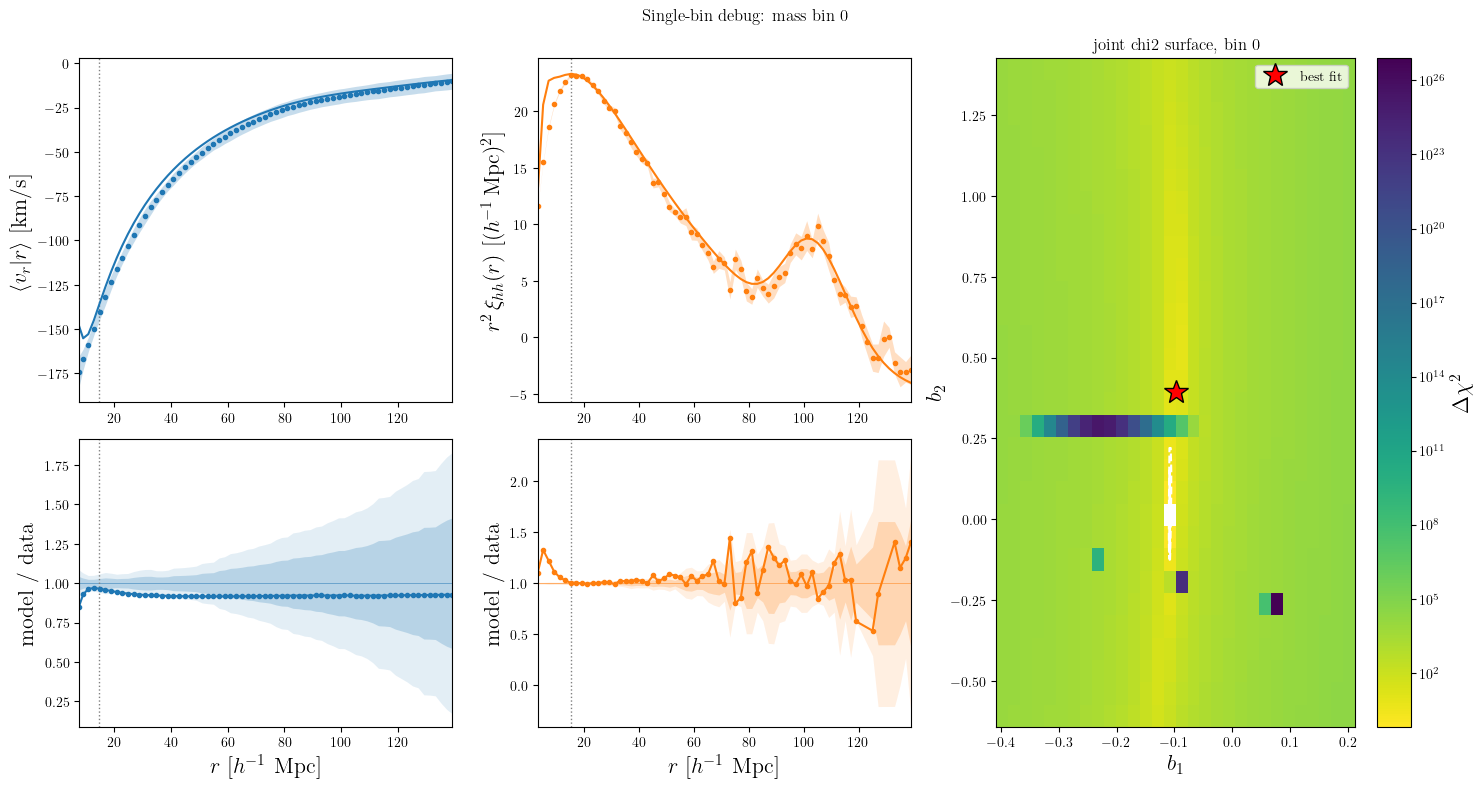

In [16]:
FID_COSMO = [0.6736, 0.02237, 0.1200, 2.083e-9, 0.9649]   # h, ombh2, omch2, As, ns --
                                                            # official AbacusSummit c000 (arXiv:2110.11413)
FID_REDSHIFT = 0.2
R_MIN_FIT = 15.0

lpt = GetLPTInputs(redshift=FID_REDSHIFT, cosmo=FID_COSMO)
lpt.get_pklin_gsm()

def model_xihh(r, b1, b2, bs=0.0):
    pars = np.array([b1, b2, bs, 0, 0, 0, 0, 0, 0])
    return lpt.xi_real(r, pars)

def model_vr(r, b1, b2, bs=0.0):
    pars = np.array([b1, b2, bs, 0, 0, 0, 0, 0, 0])
    lpt._ensure_cumulants(pars)
    v_int = np.interp(r, lpt.gsm.rint, lpt.gsm.veft)
    xi_consistent = lpt.gsm.compute_xi_real(r, *pars)
    return lpt.conv * lpt.f * v_int / (1 + xi_consistent)


def regularized_pinv(cov, max_rank):
    vals, vecs = np.linalg.eigh(cov)
    order = np.argsort(vals)[::-1]
    vals, vecs = vals[order], vecs[:, order]
    max_rank = min(max_rank, len(vals))
    vals = np.clip(vals[:max_rank], 1e-300, None)
    vecs = vecs[:, :max_rank]
    return vecs @ np.diag(1.0 / vals) @ vecs.T


def fit_bias(r_min=15.0, fit_bs=False, mode='joint',
             r_xi=None, xihh=None, cov_xi=None,
             r_vr=None, vr=None, cov_vr=None,
             max_rank=None, popsize=15, maxiter=150, tol=1e-6, seed=0):
    if mode in ('joint', 'xi'):
        m_xi = r_xi > r_min
        r_xi_fit, xihh_fit = r_xi[m_xi], xihh[m_xi]
        cov_xi_fit = cov_xi[np.ix_(m_xi, m_xi)]
        rank_xi = max_rank or max(1, m_xi.sum())
        inv_cov_xi = regularized_pinv(cov_xi_fit, rank_xi)
    if mode in ('joint', 'vr'):
        m_vr = r_vr > r_min
        r_vr_fit, vr_fit = r_vr[m_vr], vr[m_vr]
        cov_vr_fit = cov_vr[np.ix_(m_vr, m_vr)]
        rank_vr = max_rank or max(1, m_vr.sum())
        inv_cov_vr = regularized_pinv(cov_vr_fit, rank_vr)

    def loss(params):
        b1, b2 = params[0], params[1]
        bs = params[2] if fit_bs else 0.0
        c = 0.0
        if mode in ('joint', 'xi'):
            res = model_xihh(r_xi_fit, b1, b2, bs) - xihh_fit
            c += res @ inv_cov_xi @ res
        if mode in ('joint', 'vr'):
            res = model_vr(r_vr_fit, b1, b2, bs) - vr_fit
            c += res @ inv_cov_vr @ res
        return c

    bounds = [(-1.0, 5.0), (-10.0, 10.0)] + ([(-5.0, 5.0)] if fit_bs else [])
    result = differential_evolution(loss, bounds, tol=tol, seed=seed,
                                     maxiter=maxiter, popsize=popsize, polish=True)

    n_data = 0
    if mode in ('joint', 'xi'):
        n_data += len(xihh_fit)
    if mode in ('joint', 'vr'):
        n_data += len(vr_fit)
    result.dof = max(n_data - len(bounds), 1)
    result.chi2 = result.fun
    result.reduced_chi2 = result.fun / result.dof
    return result


def chi2_grid(mode, b1_grid, b2_grid, r_min=15.0, max_rank=None,
              r_xi=None, xihh=None, cov_xi=None, r_vr=None, vr=None, cov_vr=None):
    if mode in ('joint', 'xi'):
        m_xi = r_xi > r_min
        r_xi_fit, xihh_fit = r_xi[m_xi], xihh[m_xi]
        inv_cov_xi = regularized_pinv(cov_xi[np.ix_(m_xi, m_xi)], max_rank or max(1, m_xi.sum()))
    if mode in ('joint', 'vr'):
        m_vr = r_vr > r_min
        r_vr_fit, vr_fit = r_vr[m_vr], vr[m_vr]
        inv_cov_vr = regularized_pinv(cov_vr[np.ix_(m_vr, m_vr)], max_rank or max(1, m_vr.sum()))

    chi2 = np.zeros((len(b1_grid), len(b2_grid)))
    for i, b1 in enumerate(b1_grid):
        for j, b2 in enumerate(b2_grid):
            c = 0.0
            if mode in ('joint', 'xi'):
                res = model_xihh(r_xi_fit, b1, b2) - xihh_fit
                c += res @ inv_cov_xi @ res
            if mode in ('joint', 'vr'):
                res = model_vr(r_vr_fit, b1, b2) - vr_fit
                c += res @ inv_cov_vr @ res
            chi2[i, j] = c
    return chi2


K_DEBUG = 0   # which mass bin -- change this and rerun to try others

with h5.File(CACHE, 'r') as hdf:
    gk = hdf['fig1'][f'mbin_{K_DEBUG}']
    r_xi, xihh, cov_xi = gk['r_cens'][()], gk['xi'][()], gk['cov'][()]
    r_vr, vr, cov_vr = gk['vr_r'][()], gk['vr_mean'][()], 1000*gk['vr_cov'][()]
    vr_n = gk['vr_npairs'][()]
    good = np.isfinite(vr) & (vr_n > 1000) & (np.diag(cov_vr) > 0)
    r_vr, vr = r_vr[good], vr[good]
    cov_vr = cov_vr[np.ix_(good, good)]
    n_phases = gk.attrs['n_phases']
    max_rank = max(1, n_phases - 2)

res = fit_bias(mode='joint', r_min=R_MIN_FIT, r_xi=r_xi, xihh=xihh, cov_xi=cov_xi,
               r_vr=r_vr, vr=vr, cov_vr=cov_vr, max_rank=max_rank)
b1, b2 = res.x
print(f'bin {K_DEBUG}: success={res.success}, nfev={res.nfev}, chi2={res.chi2:.3f}, '
      f'dof={res.dof}, reduced_chi2={res.reduced_chi2:.3f}, b1={b1:.3f}, b2={b2:.3f}')

xi_model = model_xihh(r_xi, b1, b2)
vr_model = model_vr(r_vr, b1, b2)

# the RuntimeWarnings from velocileptors during the fit are mostly the
# optimizer exploring (and correctly rejecting) numerically unstable corners
# of the bounded box -- what actually matters is whether the FINAL best-fit
# point itself is clean. Check that directly rather than assume.
if not (np.all(np.isfinite(xi_model)) and np.all(np.isfinite(vr_model))):
    print('WARNING: the best-fit (b1,b2) itself produces non-finite model '
          'values -- this fit is NOT trustworthy, not just noisy warnings.')
else:
    print('best-fit (b1,b2) model evaluation is fully finite -- the '
          'RuntimeWarnings during the search were rejected trial points, not this result.')
    
xi_model = model_xihh(r_xi, b1, b2)
vr_model = model_vr(r_vr, b1, b2)
xi_r2 = r_xi**2 * xihh
xi_model_r2 = r_xi**2 * xi_model
vr_err = np.sqrt(np.diag(cov_vr))
xi_err = np.sqrt(np.diag(cov_xi))

fig = plt.figure(figsize=(15, 8))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 1.2], height_ratios=[1.2, 1])
ax_vr, ax_vr_r = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[1, 0])
ax_xi, ax_xi_r = fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 1])
ax_like = fig.add_subplot(gs[:, 2])

ax_vr.plot(r_vr, vr, 'o', ms=3, c='C0', zorder=2)
ax_vr.fill_between(r_vr, vr - vr_err, vr + vr_err, color='C0', alpha=0.25, lw=0, zorder=1)
ax_vr.plot(r_vr, vr_model, '-', c='C0')
ax_vr.set_ylabel(r'$\langle v_r|r\rangle$ [km/s]')

ax_xi.plot(r_xi, xi_r2, 'o', ms=3, c='C1', zorder=2)
ax_xi.fill_between(r_xi, xi_r2 - r_xi**2*xi_err, xi_r2 + r_xi**2*xi_err, color='C1', alpha=0.25, lw=0, zorder=1)
ax_xi.plot(r_xi, xi_model_r2, '-', c='C1')
ax_xi.set_ylabel(r'$r^2\,\xi_{hh}(r)$ [$(h^{-1}\,{\rm Mpc})^2$]')

vr_ratio = vr_model / vr
vr_ratio_err = np.abs(vr_ratio) * (vr_err / np.abs(vr))
ax_vr_r.axhline(1, c='C0', lw=0.7, alpha=0.5, zorder=0)
ax_vr_r.fill_between(r_vr, 1 - 2*vr_ratio_err, 1 + 2*vr_ratio_err, color='C0', alpha=0.12, lw=0, zorder=0)
ax_vr_r.fill_between(r_vr, 1 - vr_ratio_err, 1 + vr_ratio_err, color='C0', alpha=0.22, lw=0, zorder=0)
ax_vr_r.plot(r_vr, vr_ratio, 'o-', ms=3, c='C0', zorder=2)
ax_vr_r.set_ylabel('model / data')
ax_vr_r.set_xlabel(r'$r$ [$h^{-1}$ Mpc]')

xi_ratio = xi_model / xihh
xi_ratio_err = np.abs(xi_ratio) * (xi_err / np.abs(xihh))
xi_good = np.abs(xihh) > xi_err
ax_xi_r.axhline(1, c='C1', lw=0.7, alpha=0.5, zorder=0)
ax_xi_r.fill_between(r_xi[xi_good], 1 - 2*xi_ratio_err[xi_good], 1 + 2*xi_ratio_err[xi_good],
                      color='C1', alpha=0.12, lw=0, zorder=0)
ax_xi_r.fill_between(r_xi[xi_good], 1 - xi_ratio_err[xi_good], 1 + xi_ratio_err[xi_good],
                      color='C1', alpha=0.22, lw=0, zorder=0)
ax_xi_r.plot(r_xi[xi_good], xi_ratio[xi_good], 'o-', ms=3, c='C1', zorder=2)
ax_xi_r.set_ylabel('model / data')
ax_xi_r.set_xlabel(r'$r$ [$h^{-1}$ Mpc]')

for ax_ in (ax_vr, ax_vr_r, ax_xi, ax_xi_r):
    ax_.axvline(R_MIN_FIT, color='gray', ls=':', lw=1, zorder=0)
    ax_.margins(x=0)

# --- the actual joint chi2(b1,b2) surface, centered on the best fit ---
b1_grid = np.linspace(max(-1.0, b1 - 0.3), b1 + 0.3, 30)
b2_grid = np.linspace(b2 - 1.0, b2 + 1.0, 30)
chi2_2d = chi2_grid('joint', b1_grid, b2_grid, r_min=R_MIN_FIT, max_rank=max_rank,
                     r_xi=r_xi, xihh=xihh, cov_xi=cov_xi, r_vr=r_vr, vr=vr, cov_vr=cov_vr)
dchi2_2d = chi2_2d - chi2_2d.min()
B1, B2 = np.meshgrid(b1_grid, b2_grid, indexing='ij')

im = ax_like.pcolormesh(B1, B2, dchi2_2d, shading='auto', cmap='viridis_r', norm='log')#vmax=15
fig.colorbar(im, ax=ax_like, label=r'$\Delta\chi^2$')
ax_like.contour(B1, B2, dchi2_2d, levels=[2.3, 6.18], colors='white', linestyles=['-', '--'])
ax_like.plot(b1, b2, '*', c='red', ms=18, mec='k', label='best fit')
ax_like.set_xlabel(r'$b_1$')
ax_like.set_ylabel(r'$b_2$')
ax_like.set_title(f'joint chi2 surface, bin {K_DEBUG}')
ax_like.legend()

fig.suptitle(f'Single-bin debug: mass bin {K_DEBUG}')
fig.tight_layout()

In [ ]:
from ipywidgets import interact, FloatSlider

def plot_manual(b1=1.0, b2=0.0, bs=0.0):
    xi_model_m = model_xihh(r_xi, b1, b2, bs)
    vr_model_m = model_vr(r_vr, b1, b2, bs)

    fig, ax = plt.subplots(2, 2, figsize=(11, 7), sharex='col',
                            gridspec_kw={'height_ratios': [1.2, 1]})

    ax[0, 0].plot(r_vr, vr, 'o', ms=3, c='C0', zorder=2)
    ax[0, 0].fill_between(r_vr, vr - vr_err, vr + vr_err, color='C0', alpha=0.25, lw=0, zorder=1)
    ax[0, 0].plot(r_vr, vr_model_m, '-', c='C0')
    ax[0, 0].set_ylabel(r'$\langle v_r|r\rangle$ [km/s]')

    xi_r2_m = r_xi**2 * xi_model_m
    ax[0, 1].plot(r_xi, xi_r2, 'o', ms=3, c='C1', zorder=2)
    ax[0, 1].fill_between(r_xi, xi_r2 - r_xi**2*xi_err, xi_r2 + r_xi**2*xi_err,
                           color='C1', alpha=0.25, lw=0, zorder=1)
    ax[0, 1].plot(r_xi, xi_r2_m, '-', c='C1')
    ax[0, 1].set_ylabel(r'$r^2\,\xi_{hh}(r)$ [$(h^{-1}\,{\rm Mpc})^2$]')

    vr_ratio_m = vr_model_m / vr
    vr_ratio_err_m = np.abs(vr_ratio_m) * (vr_err / np.abs(vr))
    ax[1, 0].axhline(1, c='C0', lw=0.7, alpha=0.5, zorder=0)
    ax[1, 0].fill_between(r_vr, 1 - 2*vr_ratio_err_m, 1 + 2*vr_ratio_err_m, color='C0', alpha=0.12, lw=0, zorder=0)
    ax[1, 0].fill_between(r_vr, 1 - vr_ratio_err_m, 1 + vr_ratio_err_m, color='C0', alpha=0.22, lw=0, zorder=0)
    ax[1, 0].plot(r_vr, vr_ratio_m, 'o-', ms=3, c='C0', zorder=2)
    ax[1, 0].set_ylabel('model / data')
    ax[1, 0].set_xlabel(r'$r$ [$h^{-1}$ Mpc]')

    xi_ratio_m = xi_model_m / xihh
    xi_good_m = np.abs(xihh) > xi_err
    xi_ratio_err_m = np.abs(xi_ratio_m) * (xi_err / np.abs(xihh))
    ax[1, 1].axhline(1, c='C1', lw=0.7, alpha=0.5, zorder=0)
    ax[1, 1].fill_between(r_xi[xi_good_m], 1 - 2*xi_ratio_err_m[xi_good_m], 1 + 2*xi_ratio_err_m[xi_good_m],
                           color='C1', alpha=0.12, lw=0, zorder=0)
    ax[1, 1].fill_between(r_xi[xi_good_m], 1 - xi_ratio_err_m[xi_good_m], 1 + xi_ratio_err_m[xi_good_m],
                           color='C1', alpha=0.22, lw=0, zorder=0)
    ax[1, 1].plot(r_xi[xi_good_m], xi_ratio_m[xi_good_m], 'o-', ms=3, c='C1', zorder=2)
    ax[1, 1].set_ylabel('model / data')
    ax[1, 1].set_xlabel(r'$r$ [$h^{-1}$ Mpc]')

    for ax_ in ax.flat:
        ax_.axvline(R_MIN_FIT, color='gray', ls=':', lw=1, zorder=0)
        ax_.margins(x=0)

    fig.suptitle(f'Manual (b1, b2, bs) = ({b1:.3f}, {b2:.3f}, {bs:.3f}) -- bin {K_DEBUG}')
    fig.tight_layout()
    plt.show()

interact(plot_manual,
         b1=FloatSlider(min=-1.0, max=5.0, step=0.01, value=float(b1), continuous_update=False),
         b2=FloatSlider(min=-10.0, max=10.0, step=0.01, value=float(b2), continuous_update=False),
         bs=FloatSlider(min=-5.0, max=5.0, step=0.01, value=0.0, continuous_update=False));

interactive(children=(FloatSlider(value=0.0, continuous_update=False, description='b1', max=5.0, min=-1.0, ste…

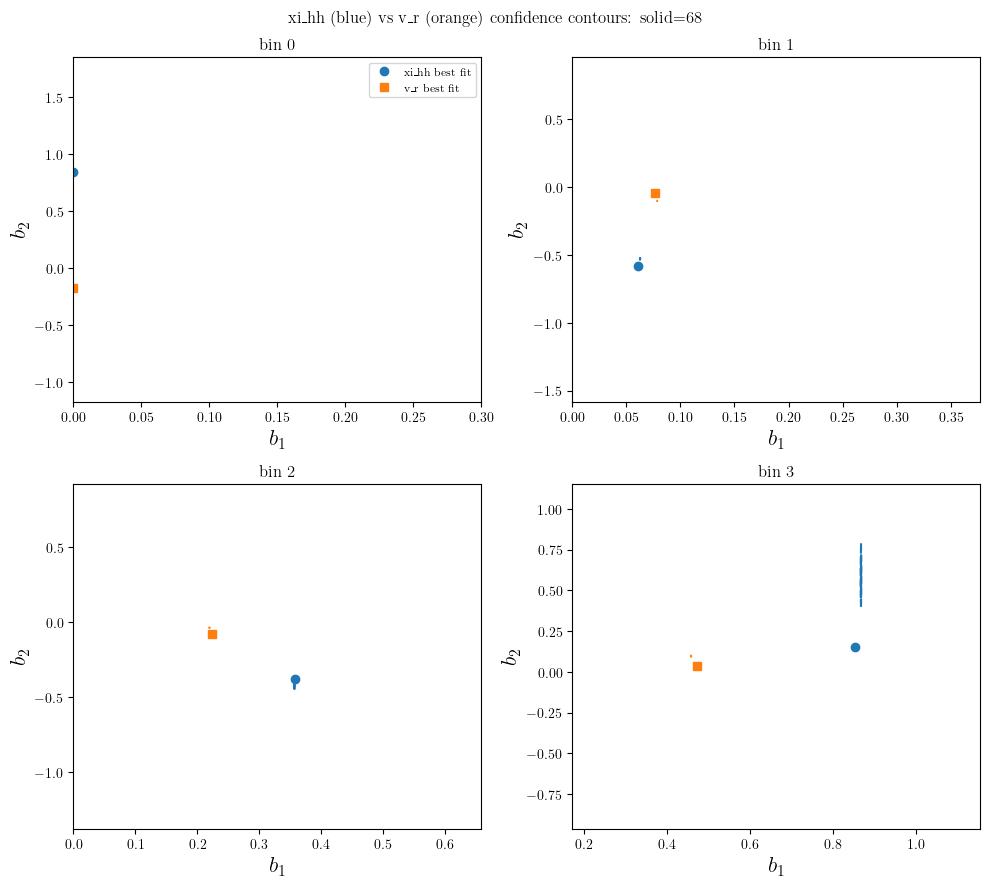

In [64]:
def chi2_grid(mode, b1_grid, b2_grid, r_min=15.0,
              r_xi=None, xihh=None, var_xi=None, r_vr=None, vr=None, var_vr=None):
    if mode in ('joint', 'xi'):
        m_xi = r_xi > r_min
        r_xi_fit, xihh_fit, var_xi_fit = r_xi[m_xi], xihh[m_xi], var_xi[m_xi]
    if mode in ('joint', 'vr'):
        m_vr = r_vr > r_min
        r_vr_fit, vr_fit, var_vr_fit = r_vr[m_vr], vr[m_vr], var_vr[m_vr]

    chi2 = np.zeros((len(b1_grid), len(b2_grid)))
    for i, b1 in enumerate(b1_grid):
        for j, b2 in enumerate(b2_grid):
            c = 0.0
            if mode in ('joint', 'xi'):
                c += np.sum((model_xihh(r_xi_fit, b1, b2) - xihh_fit)**2 / var_xi_fit)
            if mode in ('joint', 'vr'):
                c += np.sum((model_vr(r_vr_fit, b1, b2) - vr_fit)**2 / var_vr_fit)
            chi2[i, j] = c
    return chi2


with h5.File(CACHE, 'r') as hdf:
    g1 = hdf['fig1']
    mass_bins_available = sorted(int(k.split('_')[1]) for k in g1.keys())
    mass_bins_available = mass_bins_available[:-2]

    fig, axes = plt.subplots(2, 2, figsize=(10, 9))

    for ax_, k in zip(axes.flat, mass_bins_available):
        gk = g1[f'mbin_{k}']
        r_xi, xihh, cov_xi = gk['r_cens'][()], gk['xi'][()], gk['cov'][()]
        r_vr, vr, vr_sem = gk['vr_r'][()], gk['vr_mean'][()], gk['vr_sem'][()]
        vr_n = gk['vr_npairs'][()]
        good = np.isfinite(vr) & (vr_n > 1000)
        r_vr, vr, vr_var = r_vr[good], vr[good], vr_sem[good]**2
        var_xi = np.diag(cov_xi)

        res_xi = fit_bias(mode='xi', r_min=R_MIN_FIT, r_xi=r_xi, xihh=xihh, var_xi=var_xi)
        res_vr = fit_bias(mode='vr', r_min=R_MIN_FIT, r_vr=r_vr, vr=vr, var_vr=vr_var)
        b1_lo = max(0.0, min(res_xi.x[0], res_vr.x[0]) - 0.3)
        b1_hi = max(res_xi.x[0], res_vr.x[0]) + 0.3
        b2_lo = min(res_xi.x[1], res_vr.x[1]) - 1.0
        b2_hi = max(res_xi.x[1], res_vr.x[1]) + 1.0
        b1_grid = np.linspace(b1_lo, b1_hi, 25)
        b2_grid = np.linspace(b2_lo, b2_hi, 25)

        chi2_xi = chi2_grid('xi', b1_grid, b2_grid, r_min=R_MIN_FIT, r_xi=r_xi, xihh=xihh, var_xi=var_xi)
        chi2_vr = chi2_grid('vr', b1_grid, b2_grid, r_min=R_MIN_FIT, r_vr=r_vr, vr=vr, var_vr=vr_var)
        dchi2_xi = chi2_xi - chi2_xi.min()
        dchi2_vr = chi2_vr - chi2_vr.min()

        B1, B2 = np.meshgrid(b1_grid, b2_grid, indexing='ij')
        cs_xi = ax_.contour(B1, B2, dchi2_xi, levels=[2.3, 6.18], colors='C0', linestyles=['-', '--'])
        cs_vr = ax_.contour(B1, B2, dchi2_vr, levels=[2.3, 6.18], colors='C1', linestyles=['-', '--'])
        ax_.plot(*res_xi.x, 'o', c='C0', ms=6, label='xi_hh best fit')
        ax_.plot(*res_vr.x, 's', c='C1', ms=6, label='v_r best fit')
        ax_.set_title(f'bin {k}')
        ax_.set_xlabel(r'$b_1$')
        ax_.set_ylabel(r'$b_2$')

    axes.flat[0].legend(fontsize=8)
    fig.suptitle('xi_hh (blue) vs v_r (orange) confidence contours: solid=68%, dashed=95%')
    fig.tight_layout()

bin 0: xi_hh alone b1=0.000, b2=0.850, xi_reduced_chi2=94.341 -> v_r PREDICTION reduced_chi2=957.864
bin 1: xi_hh alone b1=0.061, b2=-0.584, xi_reduced_chi2=0.933 -> v_r PREDICTION reduced_chi2=1074.743


/home/cosweeney/miniconda3/envs/scienv/lib/python3.12/site-packages/velocileptors/Utils/loginterp.py:44: RuntimeWarning: overflow encountered in power
  + (xx >= x[rp]) * y[rp]* np.nan_to_num((xx/x[rp])**rneff) \


bin 2: xi_hh alone b1=0.358, b2=-0.378, xi_reduced_chi2=1.001 -> v_r PREDICTION reduced_chi2=2257.452
bin 3: xi_hh alone b1=0.853, b2=0.152, xi_reduced_chi2=1.158 -> v_r PREDICTION reduced_chi2=15692.965


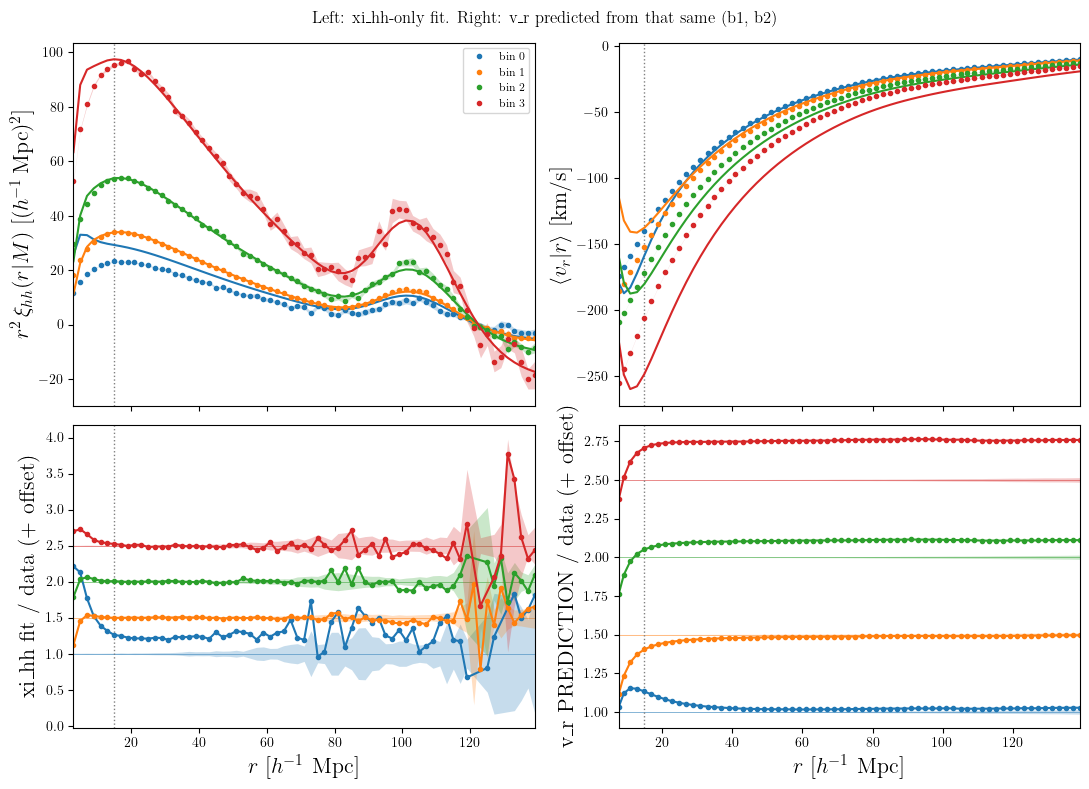

In [63]:
with h5.File(CACHE, 'r') as hdf:
    g1 = hdf['fig1']
    mass_bins_available = sorted(int(k.split('_')[1]) for k in g1.keys())
    mass_bins_available = mass_bins_available[:-2]

    # left column: xi_hh itself (the fit) -- right column: v_r (the prediction)
    fig, ax = plt.subplots(2, 2, figsize=(11, 8), sharex='col',
                            gridspec_kw={'height_ratios': [1.2, 1]})

    for n, k in enumerate(mass_bins_available):
        gk = g1[f'mbin_{k}']
        r_xi, xihh, cov_xi = gk['r_cens'][()], gk['xi'][()], gk['cov'][()]
        r_vr, vr, vr_sem = gk['vr_r'][()], gk['vr_mean'][()], gk['vr_sem'][()]
        vr_n = gk['vr_npairs'][()]
        good = np.isfinite(vr) & (vr_n > 1000)
        r_vr, vr, vr_var = r_vr[good], vr[good], vr_sem[good]**2
        var_xi = np.diag(cov_xi)

        res_xi = fit_bias(mode='xi', r_min=R_MIN_FIT, r_xi=r_xi, xihh=xihh, var_xi=var_xi)
        b1_xi, b2_xi = res_xi.x
        xi_model = model_xihh(r_xi, b1_xi, b2_xi)

        vr_pred = model_vr(r_vr, b1_xi, b2_xi)
        m_vr = r_vr > R_MIN_FIT
        vr_pred_chi2 = np.sum((vr_pred[m_vr] - vr[m_vr])**2 / vr_var[m_vr])
        vr_pred_dof = max(m_vr.sum() - 2, 1)
        vr_pred_reduced_chi2 = vr_pred_chi2 / vr_pred_dof

        print(f'bin {k}: xi_hh alone b1={b1_xi:.3f}, b2={b2_xi:.3f}, '
              f'xi_reduced_chi2={res_xi.reduced_chi2:.3f} -> '
              f'v_r PREDICTION reduced_chi2={vr_pred_reduced_chi2:.3f}')

        # --- left column: xi_hh, the fit itself ---
        xi_r2 = r_xi**2 * xihh
        xi_model_r2 = r_xi**2 * xi_model
        xi_err = np.sqrt(var_xi)

        ax[0, 0].plot(r_xi, xi_r2, 'o', ms=3, c=f'C{n}', zorder=2, label=f'bin {k}')
        ax[0, 0].fill_between(r_xi, xi_r2 - r_xi**2*xi_err, xi_r2 + r_xi**2*xi_err,
                               color=f'C{n}', alpha=0.25, lw=0, zorder=1)
        ax[0, 0].plot(r_xi, xi_model_r2, '-', c=f'C{n}')

        xi_ratio = xi_model / xihh
        xi_ratio_err = np.abs(xi_ratio) * (xi_err / np.abs(xihh))
        xi_ratio_good = np.abs(xihh) > xi_err   # mask the zero-crossing, same reasoning as Fig 1
        baseline = 1 + n*0.5
        ax[1, 0].axhline(baseline, c=f'C{n}', lw=0.7, alpha=0.5, zorder=0)
        ax[1, 0].fill_between(r_xi[xi_ratio_good], baseline - xi_ratio_err[xi_ratio_good],
                               baseline + xi_ratio_err[xi_ratio_good], color=f'C{n}', alpha=0.25, lw=0, zorder=1)
        ax[1, 0].plot(r_xi[xi_ratio_good], xi_ratio[xi_ratio_good] + n*0.5, 'o-', ms=3, c=f'C{n}', zorder=2)

        # --- right column: v_r, the out-of-sample prediction ---
        vr_err = np.sqrt(vr_var)
        ax[0, 1].plot(r_vr, vr, 'o', ms=3, c=f'C{n}', zorder=2)
        ax[0, 1].fill_between(r_vr, vr - vr_err, vr + vr_err, color=f'C{n}', alpha=0.25, lw=0, zorder=1)
        ax[0, 1].plot(r_vr, vr_pred, '-', c=f'C{n}')

        vr_ratio = vr_pred / vr
        vr_ratio_err = np.abs(vr_ratio) * (vr_err / np.abs(vr))
        ax[1, 1].axhline(baseline, c=f'C{n}', lw=0.7, alpha=0.5, zorder=0)
        ax[1, 1].fill_between(r_vr, baseline - vr_ratio_err, baseline + vr_ratio_err,
                               color=f'C{n}', alpha=0.25, lw=0, zorder=1)
        ax[1, 1].plot(r_vr, vr_ratio + n*0.5, 'o-', ms=3, c=f'C{n}', zorder=2)

    for ax_ in ax.flat:
        ax_.axvline(R_MIN_FIT, color='gray', ls=':', lw=1, zorder=0)
        ax_.margins(x=0)

    ax[0, 0].set_ylabel(r'$r^2\,\xi_{hh}(r|M)$ [$(h^{-1}\,{\rm Mpc})^2$]')
    ax[0, 1].set_ylabel(r'$\langle v_r|r\rangle$ [km/s]')
    ax[1, 0].set_ylabel('xi_hh fit / data (+ offset)')
    ax[1, 1].set_ylabel('v_r PREDICTION / data (+ offset)')
    ax[1, 0].set_xlabel(r'$r$ [$h^{-1}$ Mpc]')
    ax[1, 1].set_xlabel(r'$r$ [$h^{-1}$ Mpc]')
    ax[0, 0].legend(fontsize=8)
    fig.suptitle('Left: xi_hh-only fit. Right: v_r predicted from that same (b1, b2)')
    fig.tight_layout()

combined wide-mass joint fit: success=True, nit=605, loss=-1245, b1=0.108, b2=-0.042, eps_xi=0.0458, eps_v=0.00139


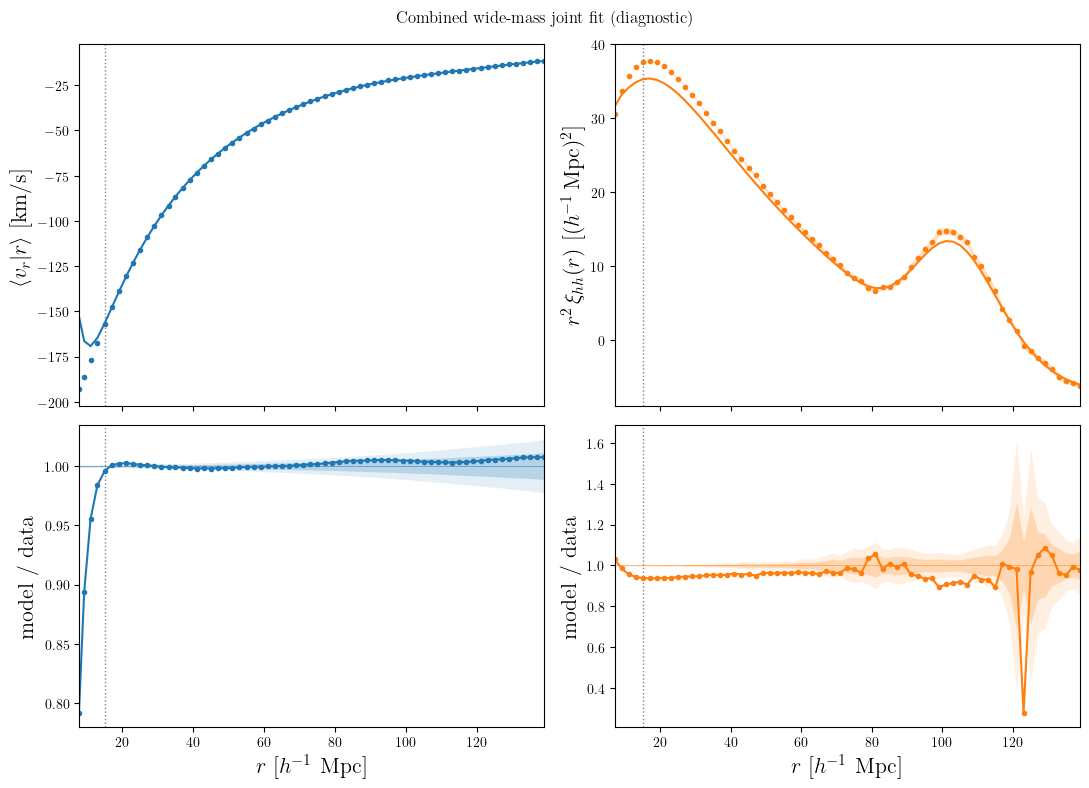

In [49]:
with h5.File(CACHE, 'r') as hdf:
    gw = hdf['fig1_wide']
    r_xi_raw, xihh_raw, cov_xi_raw = gw['r_cens'][()], gw['xi'][()], gw['cov'][()]
    r_vr_raw, vr_raw, vr_sem_raw = gw['vr_r'][()], gw['vr_mean'][()], gw['vr_sem'][()]
    vr_n = gw['vr_npairs'][()]

    good = np.isfinite(vr_raw) & (vr_n > 1000)
    r_xi, xihh_avg = r_xi_raw[good], xihh_raw[good]
    cov_xi_avg = cov_xi_raw[np.ix_(good, good)]
    r_vr_avg, vr_avg, vr_var_avg = r_vr_raw[good], vr_raw[good], vr_sem_raw[good]**2

    res = joint_bias_fit(r_xi, xihh_avg, np.diag(cov_xi_avg),
                         r_vr_avg, vr_avg, vr_var_avg, r_min=R_MIN_FIT)
    b1, b2, eps_xi, eps_v = res.x
    print(f'combined wide-mass joint fit: success={res.success}, nit={res.nit}, loss={res.fun:.4g}, '
          f'b1={b1:.3f}, b2={b2:.3f}, eps_xi={eps_xi:.3g}, eps_v={eps_v:.3g}')

    xi_model_avg = model_xihh(r_xi, b1, b2)
    vr_model_avg = model_vr(r_vr_avg, b1, b2)
    xi_err_avg = np.sqrt(np.diag(cov_xi_avg))
    vr_err_avg = np.sqrt(vr_var_avg)

    fig, ax = plt.subplots(2, 2, figsize=(11, 8), sharex='col',
                            gridspec_kw={'height_ratios': [1.2, 1]})

    ax[0, 0].plot(r_vr_avg, vr_avg, 'o', ms=3, c='C0', zorder=2)
    ax[0, 0].fill_between(r_vr_avg, vr_avg - vr_err_avg, vr_avg + vr_err_avg,
                           color='C0', alpha=0.25, lw=0, zorder=1)
    ax[0, 0].plot(r_vr_avg, vr_model_avg, '-', c='C0')

    ax[0, 1].plot(r_xi, r_xi**2*xihh_avg, 'o', ms=3, c='C1', zorder=2)
    ax[0, 1].fill_between(r_xi, r_xi**2*(xihh_avg - xi_err_avg), r_xi**2*(xihh_avg + xi_err_avg),
                           color='C1', alpha=0.25, lw=0, zorder=1)
    ax[0, 1].plot(r_xi, r_xi**2*xi_model_avg, '-', c='C1')

    vr_ratio = vr_model_avg / vr_avg
    vr_ratio_err = np.abs(vr_ratio) * (vr_err_avg / np.abs(vr_avg))
    ax[1, 0].axhline(1, c='C0', lw=0.7, alpha=0.5, zorder=0)
    ax[1, 0].fill_between(r_vr_avg, 1 - 2*vr_ratio_err, 1 + 2*vr_ratio_err, color='C0', alpha=0.12, lw=0, zorder=0)
    ax[1, 0].fill_between(r_vr_avg, 1 - vr_ratio_err, 1 + vr_ratio_err, color='C0', alpha=0.22, lw=0, zorder=0)
    ax[1, 0].plot(r_vr_avg, vr_ratio, 'o-', ms=3, c='C0', zorder=2)

    xi_ratio = xi_model_avg / xihh_avg
    xi_ratio_err = np.abs(xi_ratio) * (xi_err_avg / np.abs(xihh_avg))
    xi_good = np.abs(xihh_avg) > xi_err_avg
    ax[1, 1].axhline(1, c='C1', lw=0.7, alpha=0.5, zorder=0)
    ax[1, 1].fill_between(r_xi[xi_good], 1 - 2*xi_ratio_err[xi_good], 1 + 2*xi_ratio_err[xi_good],
                           color='C1', alpha=0.12, lw=0, zorder=0)
    ax[1, 1].fill_between(r_xi[xi_good], 1 - xi_ratio_err[xi_good], 1 + xi_ratio_err[xi_good],
                           color='C1', alpha=0.22, lw=0, zorder=0)
    ax[1, 1].plot(r_xi[xi_good], xi_ratio[xi_good], 'o-', ms=3, c='C1', zorder=2)

    for ax_ in ax.flat:
        ax_.axvline(R_MIN_FIT, color='gray', ls=':', lw=1, zorder=0)
        ax_.margins(x=0)

    ax[0, 0].set_ylabel(r'$\langle v_r|r\rangle$ [km/s]')
    ax[0, 1].set_ylabel(r'$r^2\,\xi_{hh}(r)$ [$(h^{-1}\,{\rm Mpc})^2$]')
    ax[1, 0].set_ylabel('model / data')
    ax[1, 1].set_ylabel('model / data')
    ax[1, 0].set_xlabel(r'$r$ [$h^{-1}$ Mpc]')
    ax[1, 1].set_xlabel(r'$r$ [$h^{-1}$ Mpc]')
    fig.suptitle('Combined wide-mass joint fit (diagnostic)')
    fig.tight_layout()

In [50]:
def single_fit_xihh(r_xi, xihh, var_xi, x0=(1.0, 0.0, 1e-3), r_min=15.0, tol=1e-8, maxiter=2000):
    m = r_xi > r_min
    r_fit, xi_fit, var_fit = r_xi[m], xihh[m], var_xi[m]

    def loss(b):
        b1, b2, eps = b
        model = model_xihh(r_fit, b1, b2)
        sigma2_soft = var_fit + eps**2 * xi_fit**2
        return np.sum((model - xi_fit)**2 / sigma2_soft + np.log(sigma2_soft))

    bounds = [(0.0, 5.0), (-25.0, 25.0), (0.0, np.inf)]
    result = minimize(loss, x0=x0, bounds=bounds, method='Nelder-Mead',
                       options=dict(xatol=tol, fatol=tol, maxiter=maxiter))
    return result


def single_fit_vr(r_vr, vr, var_vr, x0=(1.0, 0.0, 1e-3), r_min=15.0, tol=1e-8, maxiter=2000):
    m = r_vr > r_min
    r_fit, vr_fit, var_fit = r_vr[m], vr[m], var_vr[m]

    def loss(b):
        b1, b2, eps = b
        model = model_vr(r_fit, b1, b2)
        sigma2_soft = var_fit + eps**2 * vr_fit**2
        return np.sum((model - vr_fit)**2 / sigma2_soft + np.log(sigma2_soft))

    bounds = [(0.0, 5.0), (-25.0, 25.0), (0.0, np.inf)]
    result = minimize(loss, x0=x0, bounds=bounds, method='Nelder-Mead',
                       options=dict(xatol=tol, fatol=tol, maxiter=maxiter))
    return result


res_xi = single_fit_xihh(r_xi, xihh_avg, np.diag(cov_xi_avg), r_min=R_MIN_FIT)
res_vr = single_fit_vr(r_vr_avg, vr_avg, vr_var_avg, r_min=R_MIN_FIT)
b1_xi, b2_xi, eps_xi_only = res_xi.x
b1_vr, b2_vr, eps_v_only = res_vr.x
print(f'xi_hh alone:  success={res_xi.success}, nit={res_xi.nit}, loss={res_xi.fun:.4g}, '
      f'b1={b1_xi:.3f}, b2={b2_xi:.3f}, eps={eps_xi_only:.3g}')
print(f'v_r alone:    success={res_vr.success}, nit={res_vr.nit}, loss={res_vr.fun:.4g}, '
      f'b1={b1_vr:.3f}, b2={b2_vr:.3f}, eps={eps_v_only:.3g}')

xi_hh alone:  success=True, nit=286, loss=-1165, b1=0.124, b2=-0.514, eps=1.26e-08
v_r alone:    success=True, nit=223, loss=-214.2, b1=0.108, b2=-0.037, eps=0.00141


## Figs 2 & 3 -- sigma_v^2(r|r_p), sigma_v^2(x), and A_rho(r_p)

Single mass bin (`sigma_delta` group holds every mass bin/phase; we index
into the one we want). Fig 2 left panel is the raw (r|r_p) view: colour
encodes r_p, x-axis is r-r_p same as the right panel, so the two panels
share the same x-range but the left keeps r_p as a visual dimension via
colour while the right is the "collapsed" x = r - r_p view that motivates
the parameterization.

In [22]:
massbins

NameError: name 'massbins' is not defined

In [23]:
np.max(r_p_arr)

np.float64(139.5)

<>:60: SyntaxWarning: invalid escape sequence '\p'
<>:60: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_771757/777926256.py:60: SyntaxWarning: invalid escape sequence '\p'
  ax3.errorbar(r_p_arr[::skip], A_rho_R[::skip], A_rho_R_err[::skip], fmt='o', c='k', ms=4, label='per-$r_\perp$ fit')


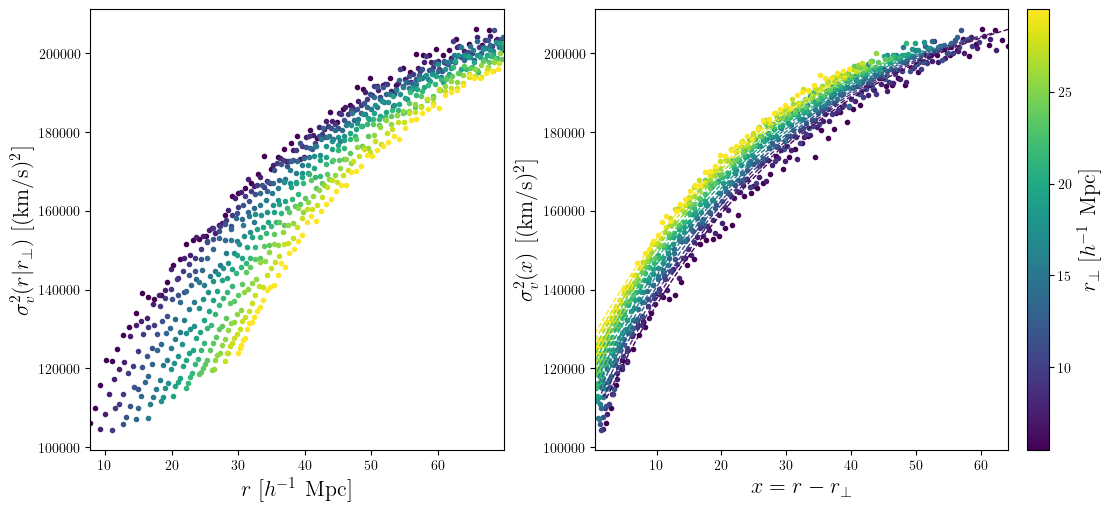

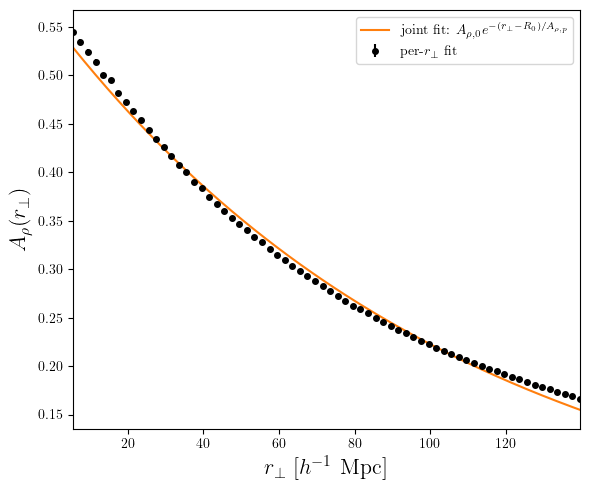

In [4]:
import matplotlib.colors as mcolors

K_SINGLE = 3   # must match K_SINGLE in gather_paper_data.py
SIM_INDEX = 0  # which cached phase to show
RP_MAX = 30.0  # h^-1 Mpc

with h5.File(CACHE, 'r') as hdf:
    sd = hdf['sigma_delta']
    r_p_arr = sd['r_p'][()]
    sig_opts = sd['sig_opts'][SIM_INDEX, K_SINGLE]     # sigma0, A_piv, b, sigma_rho
    A_rho_R = sd['A_rho_R'][SIM_INDEX, K_SINGLE]
    A_rho_R_err = sd['A_rho_R_err'][SIM_INDEX, K_SINGLE]
    R_piv = sd['R_pivs'][SIM_INDEX, K_SINGLE]

# meas_sigv / ST_pars still live in pdf_fits.h5 (not duplicated into the
# cache -- see gather_sigma_delta's docstring), so re-open that here for
# the raw per-cell values to scatter.
with h5.File('/spiffball/cosweeney/simulations/AbacusSummit_base/data/pdf_fits.h5', 'r') as hdf:
    meas_sigv = hdf['meas_sigv'][SIM_INDEX, K_SINGLE]   # (n_R, n_l)

r_p_2d, r_l_2d = np.meshgrid(r_p_arr, r_p_arr, indexing='ij')   # square grid, matches gather script
r3 = np.sqrt(r_p_2d**2 + r_l_2d**2)
x = r3 - r_p_2d

idx_plot = np.where(r_p_arr <= RP_MAX)[0]

fig, ax = plt.subplots(1, 2, figsize=(11, 5), layout='constrained')
cmap = plt.cm.viridis
norm = mcolors.Normalize(vmin=r_p_arr[idx_plot].min(), vmax=r_p_arr[idx_plot].max())
skip = 2
R_MAX = 70.0  # h^-1 Mpc, cut on 3D separation r
for j in idx_plot[::skip]:
    m = (meas_sigv[j] > 0.1) & (r3[j] <= R_MAX)
    c = cmap(norm(r_p_arr[j]))
    ax[0].plot(r3[j][m], meas_sigv[j][m]**2, 'o', ms=3, c=c)
    ax[1].plot(x[j][m], meas_sigv[j][m]**2, 'o', ms=3, c=c)

for j in idx_plot[::skip]:
    m = (meas_sigv[j] > 0.1) & (r3[j] <= R_MAX)
    xs = np.linspace(x[j][m].min(), x[j][m].max(), 500)
    A_here = A_rho_mod(r_p_arr[j], sig_opts[1], sig_opts[2], R_piv)
    ax[1].plot(xs, sigma_mod(xs, sig_opts[0], A_here, sig_opts[3])**2,
'--', c=cmap(norm(r_p_arr[j])), lw=1)

ax[0].set_xlabel(r'$r$ [$h^{-1}$ Mpc]'); ax[0].set_ylabel(r'$\sigma_v^2(r|r_\perp)$ [(km/s)$^2$]')
ax[1].set_xlabel(r'$x = r - r_\perp$'); ax[1].set_ylabel(r'$\sigma_v^2(x)$ [(km/s)$^2$]')
#ax[0].set_yscale('log'); ax[1].set_yscale('log'); ax[1].set_xscale('log')
ax[0].margins(x=0)
ax[1].margins(x=0)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
fig.colorbar(sm, ax=ax, location='right', pad=0.02, label=r'$r_\perp$ [$h^{-1}$ Mpc]')

# fig.suptitle(f'Fig 2: mass bin {K_SINGLE}, fiducial cosmology')
# fig.tight_layout()

# --- Fig 3: A_rho(r_p) ---
fig3, ax3 = plt.subplots(figsize=(6, 5))
ax3.errorbar(r_p_arr[::skip], A_rho_R[::skip], A_rho_R_err[::skip], fmt='o', c='k', ms=4, label='per-$r_\perp$ fit')
ax3.plot(r_p_arr, A_rho_mod(r_p_arr, sig_opts[1], sig_opts[2], R_piv), c='C1',
         label=r'joint fit: $A_{\rho,0}e^{-(r_\perp-R_0)/A_{\rho, p}}$')
ax3.set_xlabel(r'$r_\perp$ [$h^{-1}$ Mpc]'); ax3.set_ylabel(r'$A_\rho(r_\perp)$')
ax3.legend()
ax3.margins(x=0)
fig3.tight_layout()

## Fig 4 -- Delta(r|r_p) and Delta(x), same mass bin as Fig 2

In [6]:
LOG_MASS_EDGES = np.array([[12, 12.01], [12.5, 12.6], [13, 13.1],
                            [13.5, 13.6], [14.0, 14.2], [14.4, 14.7]])

<>:34: SyntaxWarning: invalid escape sequence '\i'
<>:34: SyntaxWarning: invalid escape sequence '\i'
/tmp/ipykernel_768406/518199566.py:34: SyntaxWarning: invalid escape sequence '\i'
  fig.suptitle(f'$M \in [{LOG_MASS_EDGES[K_SINGLE][0]}, {LOG_MASS_EDGES[K_SINGLE][1]}]$')


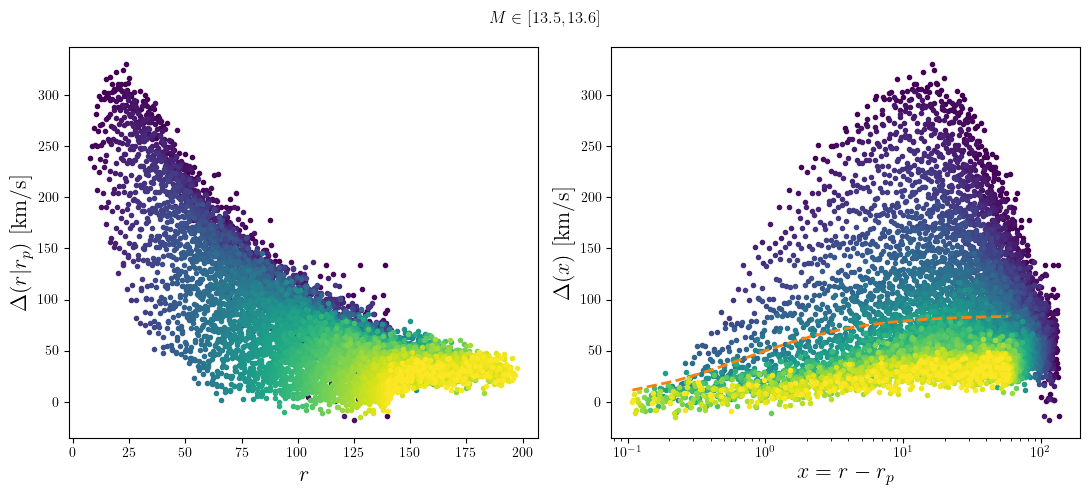

In [5]:
K_SINGLE = 3   # must match K_SINGLE in gather_paper_data.py
SIM_INDEX = 0  # which cached phase to show
RP_MAX = 140.0  # h^-1 Mpc

with h5.File(CACHE, 'r') as hdf:
    del_opts = hdf['sigma_delta']['del_opts'][SIM_INDEX, K_SINGLE]

with h5.File('/spiffball/cosweeney/simulations/AbacusSummit_base/data/pdf_fits.h5', 'r') as hdf:
    ST_pars = hdf['ST_pars'][SIM_INDEX, K_SINGLE]   # (n_R, n_l, 3): xi, omega, alpha

# need <v_r|r> to form Delta = xi_st - mean_vr(r); pulled from the fig1 cache
# for the same mass bin (vr_r/vr_mean were saved there already)
with h5.File(CACHE, 'r') as hdf:
    vr_r = hdf['fig1'][f'mbin_{K_SINGLE}']['vr_r'][()]
    vr_mean = hdf['fig1'][f'mbin_{K_SINGLE}']['vr_mean'][()]
good = np.isfinite(vr_mean)
mean_vr_interp = InterpolatedUnivariateSpline(vr_r[good], vr_mean[good], k=3, ext=3)

Delta = ST_pars[:, :, 0] - mean_vr_interp(r3) * r_l_2d / r3

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
for j in range(0, len(r_p_arr), skip):
    m = Delta[j] > -1000
    c = cmap(j / len(r_p_arr))
    ax[0].plot(r3[j][m], Delta[j][m], 'o', ms=3, c=c)
    ax[1].plot(x[j][m], Delta[j][m], 'o', ms=3, c=c)

xs = np.linspace(x[j].min(), x[j].max(), 500)

ax[1].plot(xs, delta_mod(xs, *del_opts), 'C1--', lw=2)
ax[0].set_xlabel(r'$r$'); ax[0].set_ylabel(r'$\Delta(r|r_p)$ [km/s]')
ax[1].set_xlabel(r'$x = r - r_p$'); ax[1].set_ylabel(r'$\Delta(x)$ [km/s]')
ax[1].set_xscale('log')
fig.suptitle(f'$M \in [{LOG_MASS_EDGES[K_SINGLE][0]}, {LOG_MASS_EDGES[K_SINGLE][1]}]$')
fig.tight_layout()

<>:44: SyntaxWarning: invalid escape sequence '\i'
<>:44: SyntaxWarning: invalid escape sequence '\i'
/tmp/ipykernel_758487/403483546.py:44: SyntaxWarning: invalid escape sequence '\i'
  fig.suptitle(f'$M \in [{LOG_MASS_EDGES[K_SINGLE][0]}, {LOG_MASS_EDGES[K_SINGLE][1]}]$')


Text(0.5, 0.98, '$M \\in [13.5, 13.6]$')

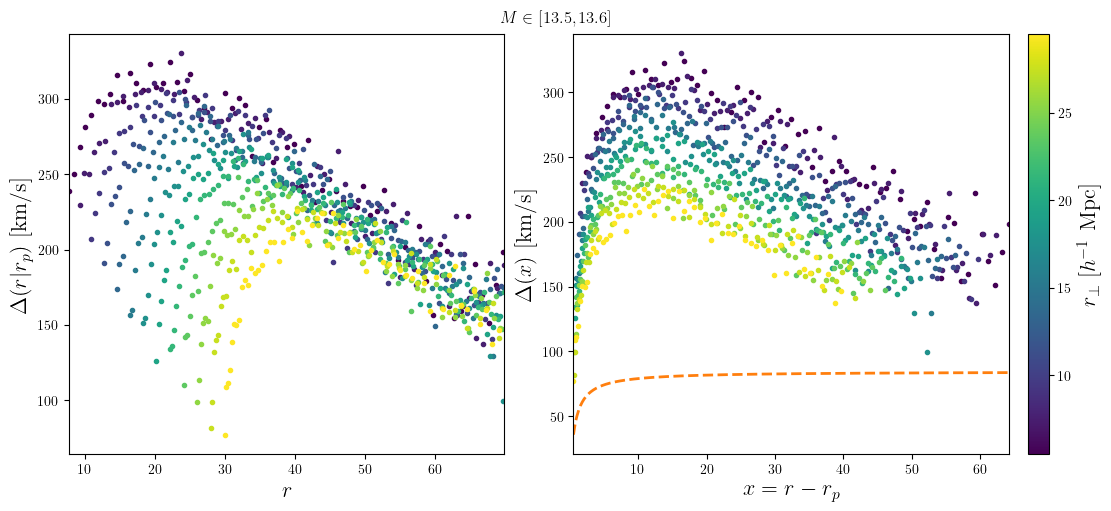

In [13]:
import matplotlib.colors as mcolors

K_SINGLE = 3   # must match K_SINGLE in gather_paper_data.py
SIM_INDEX = 0  # which cached phase to show
RP_MAX = 30.0  # h^-1 Mpc


with h5.File(CACHE, 'r') as hdf:
    del_opts = hdf['sigma_delta']['del_opts'][SIM_INDEX, K_SINGLE]

with h5.File('/spiffball/cosweeney/simulations/AbacusSummit_base/data/pdf_fits.h5', 'r') as hdf:
    ST_pars = hdf['ST_pars'][SIM_INDEX, K_SINGLE]   # (n_R, n_l, 3): xi, omega, alpha

# need <v_r|r> to form Delta = xi_st - mean_vr(r); pulled from the fig1 cache
# for the same mass bin (vr_r/vr_mean were saved there already)
with h5.File(CACHE, 'r') as hdf:
    vr_r = hdf['fig1'][f'mbin_{K_SINGLE}']['vr_r'][()]
    vr_mean = hdf['fig1'][f'mbin_{K_SINGLE}']['vr_mean'][()]
good = np.isfinite(vr_mean)
mean_vr_interp = InterpolatedUnivariateSpline(vr_r[good], vr_mean[good], k=3, ext=3)

Delta = ST_pars[:, :, 0] - mean_vr_interp(r3) * r_l_2d / r3

fig, ax = plt.subplots(1, 2, figsize=(11, 5), layout='constrained')
for j in idx_plot[::skip]:
    m = (Delta[j] > -1000) & (r3[j] <= R_MAX)
    c = cmap(norm(r_p_arr[j]))
    ax[0].plot(r3[j][m], Delta[j][m], 'o', ms=3, c=c)
    ax[1].plot(x[j][m], Delta[j][m], 'o', ms=3, c=c)

xs_mask = (Delta[idx_plot] > -1000) & (r3[idx_plot] <= R_MAX)
xs = np.linspace(x[idx_plot][xs_mask].min(), x[idx_plot][xs_mask].max(), 500)
ax[1].plot(xs, delta_mod(xs, *del_opts), 'C1--', lw=2)

ax[0].set_xlabel(r'$r$'); ax[0].set_ylabel(r'$\Delta(r|r_p)$ [km/s]')
ax[1].set_xlabel(r'$x = r - r_p$'); ax[1].set_ylabel(r'$\Delta(x)$ [km/s]')
#ax[1].set_xscale('log')
ax[0].margins(x=0)
ax[1].margins(x=0)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
fig.colorbar(sm, ax=ax, location='right', pad=0.02, label=r'$r_\perp$ [$h^{-1}$ Mpc]')
fig.suptitle(f'$M \in [{LOG_MASS_EDGES[K_SINGLE][0]}, {LOG_MASS_EDGES[K_SINGLE][1]}]$')


# fig.suptitle(f'Fig 4: mass bin {K_SINGLE}')
# fig.tight_layout()

A_delta0=74.45  r_delta=48.08  sigma_delta=8.56  beta_delta=1.71


<>:87: SyntaxWarning: invalid escape sequence '\i'
<>:91: SyntaxWarning: invalid escape sequence '\p'
<>:87: SyntaxWarning: invalid escape sequence '\i'
<>:91: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_771757/683545014.py:87: SyntaxWarning: invalid escape sequence '\i'
  fig.suptitle(f'$M \in [{LOG_MASS_EDGES[K_SINGLE][0]}, {LOG_MASS_EDGES[K_SINGLE][1]}]$')
/tmp/ipykernel_771757/683545014.py:91: SyntaxWarning: invalid escape sequence '\p'
  ax5.errorbar(r_p_arr[::skip], A_delta_R_full, A_delta_R_full_err, fmt='o', c='k', ms=4, label='per-$r_\perp$ fit')


NameError: name 'LOG_MASS_EDGES' is not defined

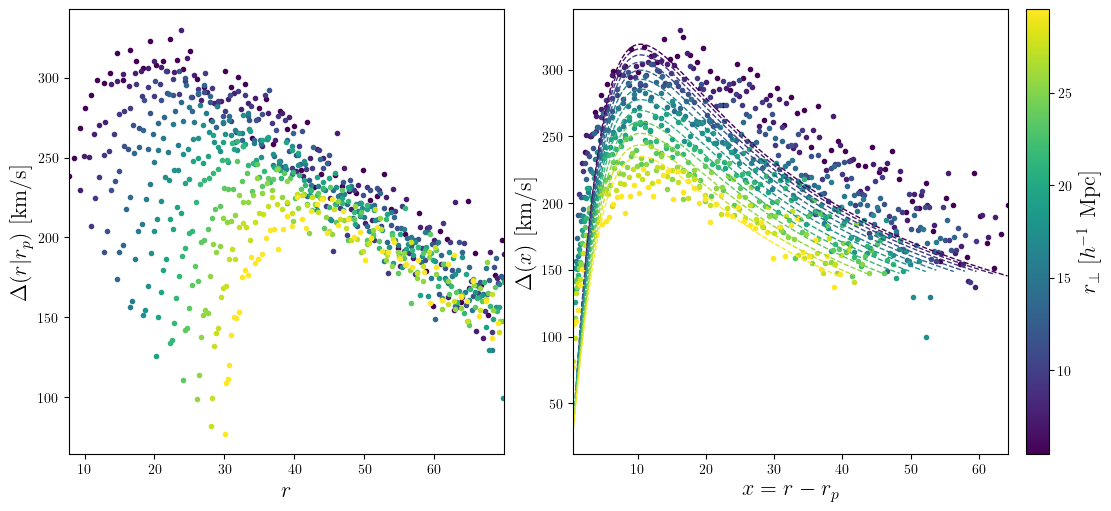

In [5]:
import matplotlib.colors as mcolors
from scipy.optimize import curve_fit

K_SINGLE = 3   # must match K_SINGLE in gather_paper_data.py
SIM_INDEX = 0  # which cached phase to show
RP_MAX = 30.0  # h^-1 Mpc

with h5.File(CACHE, 'r') as hdf:
    del_opts_cached = hdf['sigma_delta']['del_opts'][SIM_INDEX, K_SINGLE]  # old 2-param fit, used only for p0

with h5.File('/spiffball/cosweeney/simulations/AbacusSummit_base/data/pdf_fits.h5', 'r') as hdf:
    ST_pars = hdf['ST_pars'][SIM_INDEX, K_SINGLE]   # (n_R, n_l, 3): xi, omega, alpha

# need <v_r|r> to form Delta = xi_st - mean_vr(r); pulled from the fig1 cache
# for the same mass bin (vr_r/vr_mean were saved there already)
with h5.File(CACHE, 'r') as hdf:
    vr_r = hdf['fig1'][f'mbin_{K_SINGLE}']['vr_r'][()]
    vr_mean = hdf['fig1'][f'mbin_{K_SINGLE}']['vr_mean'][()]
good = np.isfinite(vr_mean)
mean_vr_interp = InterpolatedUnivariateSpline(vr_r[good], vr_mean[good], k=3, ext=3)

Delta = ST_pars[:, :, 0] - mean_vr_interp(r3) * r_l_2d / r3

# --- model: Delta(x; r_perp) = A_delta0/(1+(r_perp/r_delta)^2) * x / (1 + (x/sigma_delta)^beta_delta) ---
# amplitude form confirmed against a direct fit to the per-r_perp amplitude points (chi2_red ~ 1.05)

def A_delta_mod(R, A_delta0, r_delta):
    return A_delta0 / (1 + (R / r_delta)**2)

def delta_mod_new(x, A, sigma_delta, beta_delta):
    return A * x / (1 + (x / sigma_delta)**beta_delta)

def delta_mod_R(coords, A_delta0, r_delta, sigma_delta, beta_delta):
    x, R = coords
    return delta_mod_new(x, A_delta_mod(R, A_delta0, r_delta), sigma_delta, beta_delta)

# --- joint fit over the FULL r_p and FULL x range (no r3 cut -- R_MAX is a Fig-4 display
# choice only; restricting the fit domain to it was excluding all r_p > R_MAX entirely,
# which is why the amplitude shape diverged past ~70 before) ---
fit_mask = Delta > -1000
x_fit = x[fit_mask]
R_fit = np.broadcast_to(r_p_arr[:, None], r3.shape)[fit_mask]
Delta_fit = Delta[fit_mask]

p0 = [125.0, 50.0, 10.0, 2.0]  # A_delta0, r_delta from the confirmed amplitude-only fit
del_opts_R, del_cov_R = curve_fit(delta_mod_R, (x_fit, R_fit), Delta_fit, p0=p0, maxfev=10_000)
A_delta0, r_delta, sigma_delta, beta_delta = del_opts_R
print(f'A_delta0={A_delta0:.2f}  r_delta={r_delta:.2f}  sigma_delta={sigma_delta:.2f}  beta_delta={beta_delta:.2f}')

# --- per-r_perp amplitude points over the FULL r_p range and FULL x range per bin ---
A_delta_R_full = np.full(len(r_p_arr[::skip]), np.nan)
A_delta_R_full_err = np.full(A_delta_R_full.shape, np.nan)

for n, j in enumerate(range(0, len(r_p_arr), skip)):
    m = Delta[j] > -1000
    if m.sum() < 2:
        continue
    popt, pcov = curve_fit(lambda x, A: delta_mod_new(x, A, sigma_delta, beta_delta),
                            x[j][m], Delta[j][m],
                            p0=[A_delta_mod(r_p_arr[j], A_delta0, r_delta)], maxfev=5_000)
    A_delta_R_full[n] = popt[0]
    A_delta_R_full_err[n] = np.sqrt(pcov[0, 0])

# --- Fig 4: Delta(r), Delta(x), per-bin model curves (still truncated to RP_MAX / R_MAX for display) ---
fig, ax = plt.subplots(1, 2, figsize=(11, 5), layout='constrained')
for j in idx_plot[::skip]:
    m = (Delta[j] > -1000) & (r3[j] <= R_MAX)
    c = cmap(norm(r_p_arr[j]))
    ax[0].plot(r3[j][m], Delta[j][m], 'o', ms=3, c=c)
    ax[1].plot(x[j][m], Delta[j][m], 'o', ms=3, c=c)

for j in idx_plot[::skip]:
    m = (Delta[j] > -1000) & (r3[j] <= R_MAX)
    xs = np.linspace(x[j][m].min(), x[j][m].max(), 500)
    A_here = A_delta_mod(r_p_arr[j], A_delta0, r_delta)
    ax[1].plot(xs, delta_mod_new(xs, A_here, sigma_delta, beta_delta),
               '--', c=cmap(norm(r_p_arr[j])), lw=1)

ax[0].set_xlabel(r'$r$'); ax[0].set_ylabel(r'$\Delta(r|r_p)$ [km/s]')
ax[1].set_xlabel(r'$x = r - r_p$'); ax[1].set_ylabel(r'$\Delta(x)$ [km/s]')
ax[0].margins(x=0)
ax[1].margins(x=0)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
fig.colorbar(sm, ax=ax, location='right', pad=0.02, label=r'$r_\perp$ [$h^{-1}$ Mpc]')
fig.suptitle(f'$M \in [{LOG_MASS_EDGES[K_SINGLE][0]}, {LOG_MASS_EDGES[K_SINGLE][1]}]$')

# --- Fig 5: A_Delta(r_perp), analogous to Fig 3 ---
fig5, ax5 = plt.subplots(figsize=(6, 5))
ax5.errorbar(r_p_arr[::skip], A_delta_R_full, A_delta_R_full_err, fmt='o', c='k', ms=4, label='per-$r_\perp$ fit')
ax5.plot(r_p_arr, A_delta_mod(r_p_arr, A_delta0, r_delta), c='C1',
         label=r'joint fit: $A_{\Delta,0}/(1+(r_\perp/r_\Delta)^2)$')
ax5.set_xlabel(r'$r_\perp$ [$h^{-1}$ Mpc]'); ax5.set_ylabel(r'$A_\Delta(r_\perp)$ [km/s]')
ax5.legend()
ax5.margins(x=0)
fig5.suptitle(f'Fig 5: mass bin {K_SINGLE}')
fig5.tight_layout()

<>:66: SyntaxWarning: invalid escape sequence '\i'
<>:70: SyntaxWarning: invalid escape sequence '\p'
<>:66: SyntaxWarning: invalid escape sequence '\i'
<>:70: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_771757/329382322.py:66: SyntaxWarning: invalid escape sequence '\i'
  fig.suptitle(f'$M \in [{LOG_MASS_EDGES[K_SINGLE][0]}, {LOG_MASS_EDGES[K_SINGLE][1]}]$')
/tmp/ipykernel_771757/329382322.py:70: SyntaxWarning: invalid escape sequence '\p'
  ax5.errorbar(r_p_arr[::skip], A_delta_R_alpha, A_delta_R_alpha_err, fmt='o', c='k', ms=4, label='per-$r_\perp$ fit')


A_delta0=157.92  r_delta=47.04  sigma_delta=37.65  beta_delta=1.84  alpha=0.300


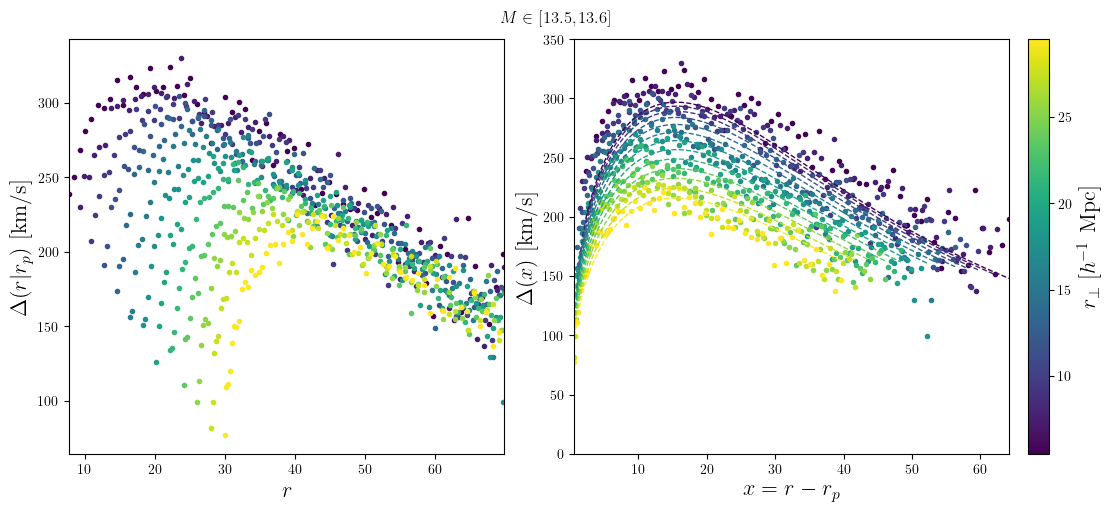

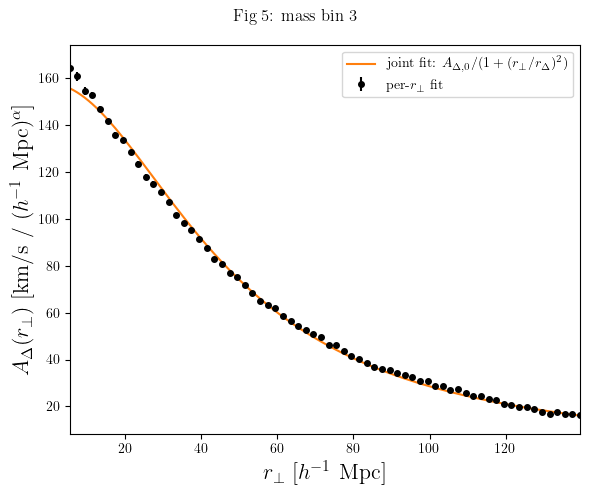

In [8]:
import matplotlib.colors as mcolors
from scipy.optimize import curve_fit

# --- model: Delta(x; r_perp) = A_delta0/(1+(r_perp/r_delta)^2) * x^alpha / (1 + (x/sigma_delta)^beta_delta) ---
# alpha is a single shared exponent, not r_perp-dependent

def delta_mod_alpha(x, A, sigma_delta, beta_delta, alpha):
    return A * x**alpha / (1 + (x / sigma_delta)**beta_delta)

def delta_mod_alpha_R(coords, A_delta0, r_delta, sigma_delta, beta_delta, alpha):
    x, R = coords
    return delta_mod_alpha(x, A_delta_mod(R, A_delta0, r_delta), sigma_delta, beta_delta, alpha)

# --- joint fit over the full r_p and x range (no r3 cut) ---
fit_mask = Delta > -1000
x_fit = x[fit_mask]
R_fit = np.broadcast_to(r_p_arr[:, None], r3.shape)[fit_mask]
Delta_fit = Delta[fit_mask]

p0_alpha = [A_delta0, r_delta, sigma_delta, beta_delta, 1.0]  # alpha=1 recovers the previous model
del_opts_alpha, del_cov_alpha = curve_fit(delta_mod_alpha_R, (x_fit, R_fit), Delta_fit,
                                           p0=p0_alpha, maxfev=20_000)
A_delta0_a, r_delta_a, sigma_delta_a, beta_delta_a, alpha = del_opts_alpha
print(f'A_delta0={A_delta0_a:.2f}  r_delta={r_delta_a:.2f}  sigma_delta={sigma_delta_a:.2f}  '
      f'beta_delta={beta_delta_a:.2f}  alpha={alpha:.3f}')

# --- per-r_perp amplitude points over the FULL r_p range, shape held fixed to the joint-fit values ---
A_delta_R_alpha = np.full(len(r_p_arr[::skip]), np.nan)
A_delta_R_alpha_err = np.full(A_delta_R_alpha.shape, np.nan)

for n, j in enumerate(range(0, len(r_p_arr), skip)):
    m = Delta[j] > -1000
    if m.sum() < 2:
        continue
    popt, pcov = curve_fit(lambda x, A: delta_mod_alpha(x, A, sigma_delta_a, beta_delta_a, alpha),
                            x[j][m], Delta[j][m],
                            p0=[A_delta_mod(r_p_arr[j], A_delta0_a, r_delta_a)], maxfev=5_000)
    A_delta_R_alpha[n] = popt[0]
    A_delta_R_alpha_err[n] = np.sqrt(pcov[0, 0])

# --- Fig 4: Delta(r), Delta(x), per-bin model curves (truncated to RP_MAX / R_MAX for display) ---
fig, ax = plt.subplots(1, 2, figsize=(11, 5), layout='constrained')
for j in idx_plot[::skip]:
    m = (Delta[j] > -1000) & (r3[j] <= R_MAX)
    c = cmap(norm(r_p_arr[j]))
    ax[0].plot(r3[j][m], Delta[j][m], 'o', ms=3, c=c)
    ax[1].plot(x[j][m], Delta[j][m], 'o', ms=3, c=c)

for j in idx_plot[::skip]:
    m = (Delta[j] > -1000) & (r3[j] <= R_MAX)
    xs = np.linspace(x[j][m].min(), x[j][m].max(), 500)
    A_here = A_delta_mod(r_p_arr[j], A_delta0_a, r_delta_a)
    ax[1].plot(xs, delta_mod_alpha(xs, A_here, sigma_delta_a, beta_delta_a, alpha),
               '--', c=cmap(norm(r_p_arr[j])), lw=1)

ax[0].set_xlabel(r'$r$'); ax[0].set_ylabel(r'$\Delta(r|r_p)$ [km/s]')
ax[1].set_xlabel(r'$x = r - r_p$'); ax[1].set_ylabel(r'$\Delta(x)$ [km/s]')
ax[0].margins(x=0)
ax[1].margins(x=0)
#ax[1].set_xscale('log')
ax[1].set_ylim((0, 350))

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
fig.colorbar(sm, ax=ax, location='right', pad=0.02, label=r'$r_\perp$ [$h^{-1}$ Mpc]')
fig.suptitle(f'$M \in [{LOG_MASS_EDGES[K_SINGLE][0]}, {LOG_MASS_EDGES[K_SINGLE][1]}]$')

# --- Fig 5: A_Delta(r_perp), full range ---
fig5, ax5 = plt.subplots(figsize=(6, 5))
ax5.errorbar(r_p_arr[::skip], A_delta_R_alpha, A_delta_R_alpha_err, fmt='o', c='k', ms=4, label='per-$r_\perp$ fit')
ax5.plot(r_p_arr, A_delta_mod(r_p_arr, A_delta0_a, r_delta_a), c='C1',
         label=r'joint fit: $A_{\Delta,0}/(1+(r_\perp/r_\Delta)^2)$')
ax5.set_xlabel(r'$r_\perp$ [$h^{-1}$ Mpc]'); ax5.set_ylabel(r'$A_\Delta(r_\perp)$ [km/s / ($h^{-1}$ Mpc)$^\alpha$]')
ax5.legend()
ax5.margins(x=0)
fig5.suptitle(f'Fig 5: mass bin {K_SINGLE}')
fig5.tight_layout()

<>:51: SyntaxWarning: invalid escape sequence '\i'
<>:51: SyntaxWarning: invalid escape sequence '\i'
/tmp/ipykernel_771757/2618269874.py:51: SyntaxWarning: invalid escape sequence '\i'
  fig.suptitle(f'$M \in [{LOG_MASS_EDGES[K_SINGLE][0]}, {LOG_MASS_EDGES[K_SINGLE][1]}]$')


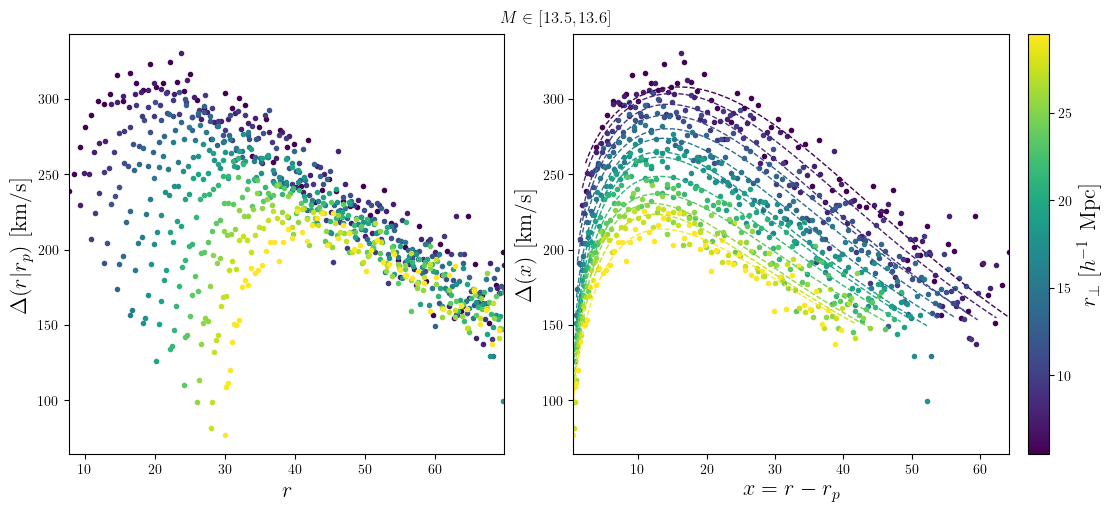

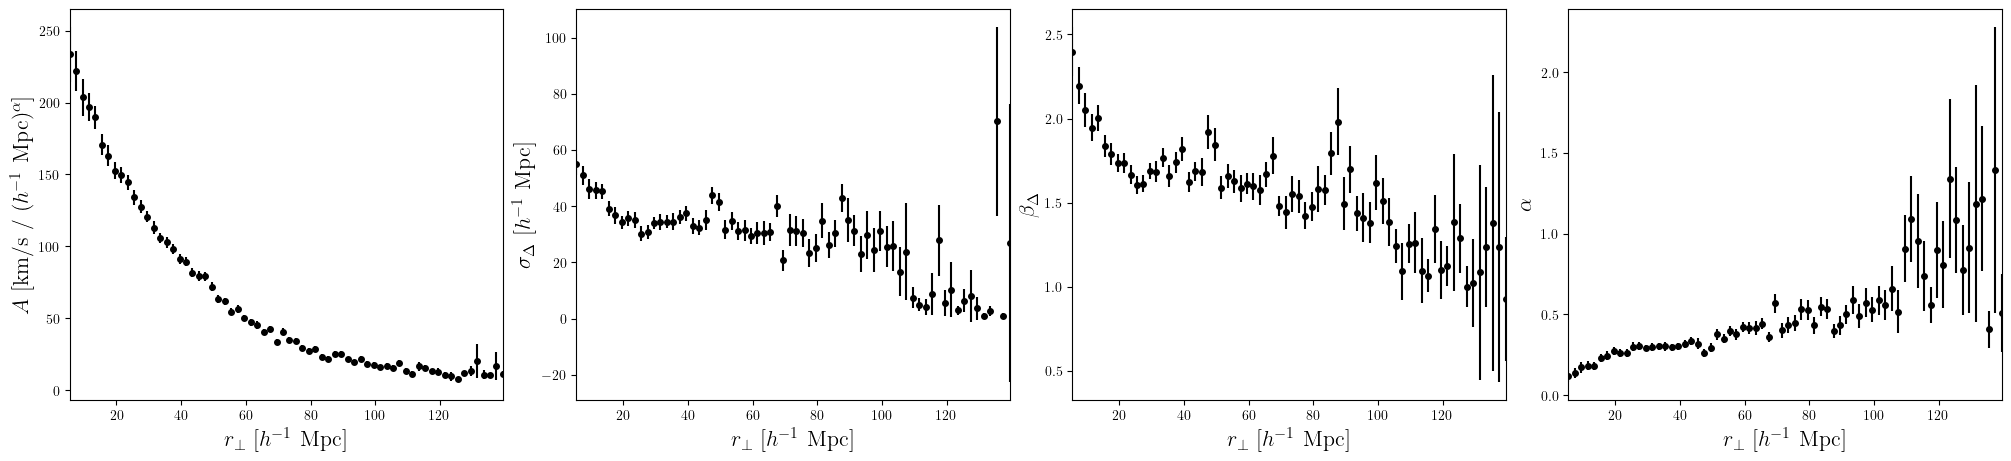

In [9]:
from scipy.optimize import curve_fit

# --- fit each r_perp bin independently over the FULL r_p range: A, sigma_delta, beta_delta, alpha free per bin ---
fit_bins = list(range(0, len(r_p_arr), skip))
bin_idx = {j: n for n, j in enumerate(fit_bins)}  # bin index -> row in fit_vals/fit_errs
n_bins = len(fit_bins)

param_names = ['A', 'sigma_delta', 'beta_delta', 'alpha']
fit_vals = np.full((n_bins, 4), np.nan)
fit_errs = np.full((n_bins, 4), np.nan)

for j in fit_bins:
    n = bin_idx[j]
    m = Delta[j] > -1000
    if m.sum() < 5:  # need at least as many points as free parameters
        continue
    p0 = [A_delta_mod(r_p_arr[j], A_delta0_a, r_delta_a), sigma_delta_a, beta_delta_a, alpha]
    try:
        popt, pcov = curve_fit(delta_mod_alpha, x[j][m], Delta[j][m], p0=p0,
                                bounds=([-np.inf, 1e-3, 1e-3, -np.inf], [np.inf, np.inf, np.inf, np.inf]),
                                maxfev=10_000)
        fit_vals[n] = popt
        fit_errs[n] = np.sqrt(np.diag(pcov))
    except RuntimeError:
        print(f'fit failed for r_p bin {j} (r_p={r_p_arr[j]:.1f})')

# --- Fig 4: Delta(r), Delta(x), limited to idx_plot for display, each bin's OWN independent fit overlaid ---
fig, ax = plt.subplots(1, 2, figsize=(11, 5), layout='constrained')
for j in idx_plot[::skip]:
    m = (Delta[j] > -1000) & (r3[j] <= R_MAX)
    c = cmap(norm(r_p_arr[j]))
    ax[0].plot(r3[j][m], Delta[j][m], 'o', ms=3, c=c)
    ax[1].plot(x[j][m], Delta[j][m], 'o', ms=3, c=c)

for j in idx_plot[::skip]:
    n = bin_idx[j]
    if not np.all(np.isfinite(fit_vals[n])):
        continue
    m = (Delta[j] > -1000) & (r3[j] <= R_MAX)
    xs = np.linspace(x[j][m].min(), x[j][m].max(), 500)
    ax[1].plot(xs, delta_mod_alpha(xs, *fit_vals[n]), '--', c=cmap(norm(r_p_arr[j])), lw=1)

ax[0].set_xlabel(r'$r$'); ax[0].set_ylabel(r'$\Delta(r|r_p)$ [km/s]')
ax[1].set_xlabel(r'$x = r - r_p$'); ax[1].set_ylabel(r'$\Delta(x)$ [km/s]')
ax[0].margins(x=0)
ax[1].margins(x=0)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
fig.colorbar(sm, ax=ax, location='right', pad=0.02, label=r'$r_\perp$ [$h^{-1}$ Mpc]')
fig.suptitle(f'$M \in [{LOG_MASS_EDGES[K_SINGLE][0]}, {LOG_MASS_EDGES[K_SINGLE][1]}]$')

# --- parameter panels: r_p dependence of each independently-fit parameter, ALL bins ---
labels = [r'$A$ [km/s / ($h^{-1}$ Mpc)$^\alpha$]', r'$\sigma_\Delta$ [$h^{-1}$ Mpc]',
          r'$\beta_\Delta$', r'$\alpha$']

fig2, ax2 = plt.subplots(1, 4, figsize=(20, 4.5), layout='constrained')
for i, label in enumerate(labels):
    ax2[i].errorbar(r_p_arr[fit_bins], fit_vals[:, i], fit_errs[:, i], fmt='o', c='k', ms=4)
    ax2[i].set_xlabel(r'$r_\perp$ [$h^{-1}$ Mpc]')
    ax2[i].set_ylabel(label)
    ax2[i].margins(x=0)

<>:18: SyntaxWarning: invalid escape sequence '\p'
<>:32: SyntaxWarning: invalid escape sequence '\c'
<>:18: SyntaxWarning: invalid escape sequence '\p'
<>:32: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_758487/217986636.py:18: SyntaxWarning: invalid escape sequence '\p'
  ax.errorbar(r_amp[good_amp], A_amp[good_amp], A_amp_err[good_amp], fmt='o', c='k', ms=4, label='per-$r_\perp$ fit', zorder=10)
/tmp/ipykernel_758487/217986636.py:32: SyntaxWarning: invalid escape sequence '\c'
  ax.plot(rs, f(rs, *popt), label=f'{name} ($\chi^2_\\nu$={chi2_red:.2f})')


flat_core_p2     A0=  120.99  s=   52.92  chi2_red=1.048
exp              A0=  146.98  s=   59.01  chi2_red=1.424
sqrt_core        A0=  157.28  s=   18.81  chi2_red=46.247
gaussian         A0=   85.64  s=   93.81  chi2_red=47.945
simple_pole      A0=  280.40  s=   11.73  chi2_red=72.558
flat_core_p4     A0=   73.79  s=   85.47  chi2_red=82.017


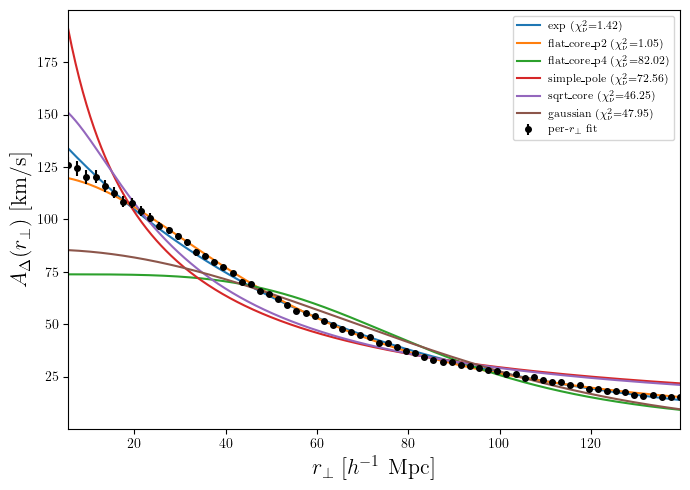

In [25]:
from scipy.optimize import curve_fit

r_amp = r_p_arr[::skip]
A_amp = A_delta_R_full
A_amp_err = A_delta_R_full_err
good_amp = np.isfinite(A_amp) & np.isfinite(A_amp_err) & (A_amp_err > 0)

candidates = {
    'exp':            lambda R, A0, s: A0 * np.exp(-R / s),
    'flat_core_p2':   lambda R, A0, s: A0 / (1 + (R / s)**2),
    'flat_core_p4':   lambda R, A0, s: A0 / (1 + (R / s)**4),
    'simple_pole':    lambda R, A0, s: A0 / (1 + R / s),
    'sqrt_core':      lambda R, A0, s: A0 / np.sqrt(1 + (R / s)**2),
    'gaussian':       lambda R, A0, s: A0 * np.exp(-(R / s)**2),
}

fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(r_amp[good_amp], A_amp[good_amp], A_amp_err[good_amp], fmt='o', c='k', ms=4, label='per-$r_\perp$ fit', zorder=10)

rs = np.linspace(r_amp[good_amp].min(), r_amp[good_amp].max(), 500)
results = {}
for name, f in candidates.items():
    try:
        popt, pcov = curve_fit(f, r_amp[good_amp], A_amp[good_amp], sigma=A_amp_err[good_amp],
                                p0=[A_amp[good_amp][0], 50.0], absolute_sigma=True, maxfev=10_000)
    except RuntimeError:
        continue
    resid = (A_amp[good_amp] - f(r_amp[good_amp], *popt)) / A_amp_err[good_amp]
    dof = good_amp.sum() - 2
    chi2_red = np.sum(resid**2) / dof
    results[name] = (popt, chi2_red)
    ax.plot(rs, f(rs, *popt), label=f'{name} ($\chi^2_\\nu$={chi2_red:.2f})')

ax.set_xlabel(r'$r_\perp$ [$h^{-1}$ Mpc]'); ax.set_ylabel(r'$A_\Delta(r_\perp)$ [km/s]')
ax.legend(fontsize=8)
ax.margins(x=0)
fig.tight_layout()

for name, (popt, chi2_red) in sorted(results.items(), key=lambda kv: kv[1][1]):
    print(f'{name:15s}  A0={popt[0]:8.2f}  s={popt[1]:8.2f}  chi2_red={chi2_red:.3f}')

<>:82: SyntaxWarning: invalid escape sequence '\i'
<>:82: SyntaxWarning: invalid escape sequence '\i'
/tmp/ipykernel_758487/3252605218.py:82: SyntaxWarning: invalid escape sequence '\i'
  fig.suptitle(f'$M \in [{LOG_MASS_EDGES[K_SINGLE][0]}, {LOG_MASS_EDGES[K_SINGLE][1]}]$')


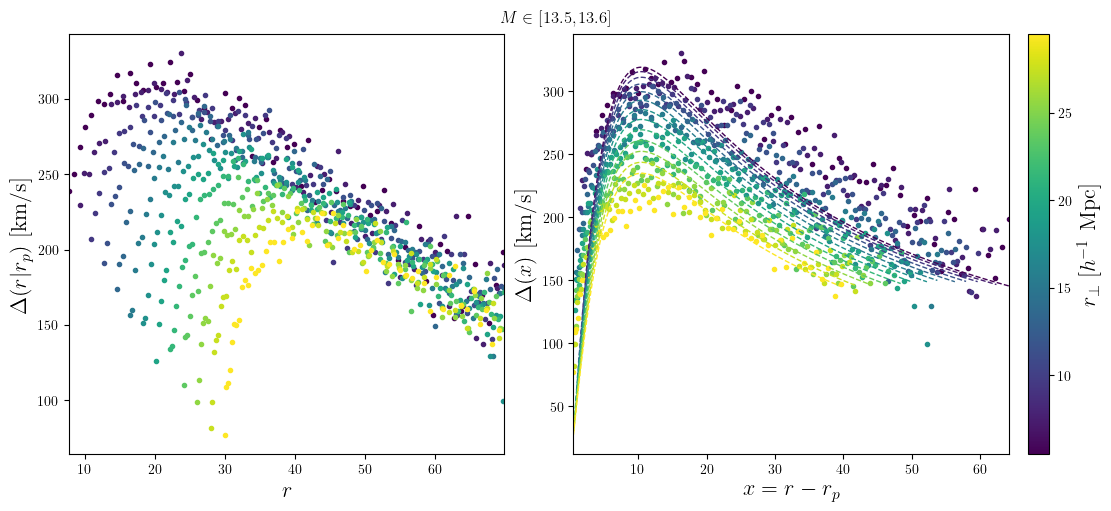

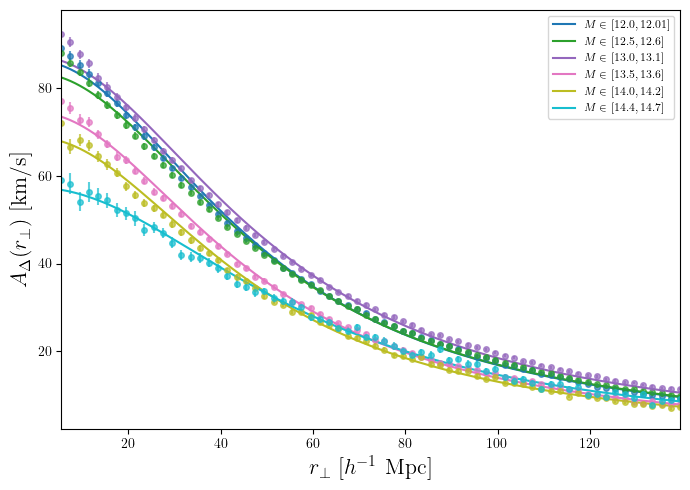

In [28]:
import matplotlib.colors as mcolors
from scipy.optimize import curve_fit

K_SINGLE = 3   # must match K_SINGLE in gather_paper_data.py
SIM_INDEX = 0  # which cached phase to show
RP_MAX = 30.0  # h^-1 Mpc

def A_delta_mod(R, A_delta0, r_delta):
    return A_delta0 / (1 + (R / r_delta)**2)

def delta_mod_new(x, A, sigma_delta, beta_delta):
    return A * x / (1 + (x / sigma_delta)**beta_delta)

def delta_mod_R(coords, A_delta0, r_delta, sigma_delta, beta_delta):
    x, R = coords
    return delta_mod_new(x, A_delta_mod(R, A_delta0, r_delta), sigma_delta, beta_delta)

def fit_delta_for_mbin(k):
    """Returns (Delta array, joint-fit params, per-r_perp amplitude points+errs) for mass bin k."""
    with h5.File('/spiffball/cosweeney/simulations/AbacusSummit_base/data/pdf_fits.h5', 'r') as hdf:
        ST_pars_k = hdf['ST_pars'][SIM_INDEX, k]

    with h5.File(CACHE, 'r') as hdf:
        vr_r_k = hdf['fig1'][f'mbin_{k}']['vr_r'][()]
        vr_mean_k = hdf['fig1'][f'mbin_{k}']['vr_mean'][()]
    good_k = np.isfinite(vr_mean_k)
    mean_vr_interp_k = InterpolatedUnivariateSpline(vr_r_k[good_k], vr_mean_k[good_k], k=3, ext=3)

    Delta_k = ST_pars_k[:, :, 0] - mean_vr_interp_k(r3) * r_l_2d / r3

    fit_mask = Delta_k > -1000
    x_fit = x[fit_mask]
    R_fit = np.broadcast_to(r_p_arr[:, None], r3.shape)[fit_mask]
    Delta_fit = Delta_k[fit_mask]

    p0 = [125.0, 50.0, 10.0, 2.0]
    del_opts_R, _ = curve_fit(delta_mod_R, (x_fit, R_fit), Delta_fit, p0=p0, maxfev=10_000)
    A_delta0_k, r_delta_k, sigma_delta_k, beta_delta_k = del_opts_R

    A_delta_R_full_k = np.full(len(r_p_arr[::skip]), np.nan)
    A_delta_R_full_err_k = np.full(A_delta_R_full_k.shape, np.nan)
    for n, j in enumerate(range(0, len(r_p_arr), skip)):
        m = Delta_k[j] > -1000
        if m.sum() < 2:
            continue
        popt, pcov = curve_fit(lambda x, A: delta_mod_new(x, A, sigma_delta_k, beta_delta_k),
                                x[j][m], Delta_k[j][m],
                                p0=[A_delta_mod(r_p_arr[j], A_delta0_k, r_delta_k)], maxfev=5_000)
        A_delta_R_full_k[n] = popt[0]
        A_delta_R_full_err_k[n] = np.sqrt(pcov[0, 0])

    return Delta_k, (A_delta0_k, r_delta_k, sigma_delta_k, beta_delta_k), (A_delta_R_full_k, A_delta_R_full_err_k)

# --- run for K_SINGLE (used below for Fig 4) ---
Delta, (A_delta0, r_delta, sigma_delta, beta_delta), (A_delta_R_full, A_delta_R_full_err) = fit_delta_for_mbin(K_SINGLE)

idx_plot = np.where(r_p_arr <= RP_MAX)[0]

# --- Fig 4: Delta(r), Delta(x), per-bin model curves (K_SINGLE only, truncated to RP_MAX / R_MAX) ---
fig, ax = plt.subplots(1, 2, figsize=(11, 5), layout='constrained')
for j in idx_plot[::skip]:
    m = (Delta[j] > -1000) & (r3[j] <= R_MAX)
    c = cmap(norm(r_p_arr[j]))
    ax[0].plot(r3[j][m], Delta[j][m], 'o', ms=3, c=c)
    ax[1].plot(x[j][m], Delta[j][m], 'o', ms=3, c=c)

for j in idx_plot[::skip]:
    m = (Delta[j] > -1000) & (r3[j] <= R_MAX)
    xs = np.linspace(x[j][m].min(), x[j][m].max(), 500)
    A_here = A_delta_mod(r_p_arr[j], A_delta0, r_delta)
    ax[1].plot(xs, delta_mod_new(xs, A_here, sigma_delta, beta_delta),
               '--', c=cmap(norm(r_p_arr[j])), lw=1)

ax[0].set_xlabel(r'$r$'); ax[0].set_ylabel(r'$\Delta(r|r_p)$ [km/s]')
ax[1].set_xlabel(r'$x = r - r_p$'); ax[1].set_ylabel(r'$\Delta(x)$ [km/s]')
ax[0].margins(x=0)
ax[1].margins(x=0)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
fig.colorbar(sm, ax=ax, location='right', pad=0.02, label=r'$r_\perp$ [$h^{-1}$ Mpc]')
fig.suptitle(f'$M \in [{LOG_MASS_EDGES[K_SINGLE][0]}, {LOG_MASS_EDGES[K_SINGLE][1]}]$')

# --- Fig 5: A_Delta(r_perp) for several mass bins ---
K_LIST = range(len(LOG_MASS_EDGES))  # all six mass bins; narrow this if you only want some
mbin_colors = plt.cm.tab10(np.linspace(0, 1, len(K_LIST)))

fig5, ax5 = plt.subplots(figsize=(7, 5))
for k, c in zip(K_LIST, mbin_colors):
    if k == K_SINGLE:
        A_delta0_k, r_delta_k, A_full_k, A_full_err_k = A_delta0, r_delta, A_delta_R_full, A_delta_R_full_err
    else:
        _, (A_delta0_k, r_delta_k, _, _), (A_full_k, A_full_err_k) = fit_delta_for_mbin(k)

    label = f'$M \\in [{LOG_MASS_EDGES[k][0]}, {LOG_MASS_EDGES[k][1]}]$'
    ax5.errorbar(r_p_arr[::skip], A_full_k, A_full_err_k, fmt='o', c=c, ms=4, alpha=0.7)
    ax5.plot(r_p_arr, A_delta_mod(r_p_arr, A_delta0_k, r_delta_k), c=c, label=label)

ax5.set_xlabel(r'$r_\perp$ [$h^{-1}$ Mpc]'); ax5.set_ylabel(r'$A_\Delta(r_\perp)$ [km/s]')
ax5.legend(fontsize=8)
ax5.margins(x=0)
fig5.tight_layout()

Pearson correlation across 15 phases, per mass bin
(n=15 per bin -- treat r as indicative, not tightly constrained)

--- corr(A_delta0, beta_delta) ---
  mass bin 0 (M=1.01e+12): r = -0.42  (p = 0.119)
  mass bin 1 (M=3.55e+12): r = -0.50  (p = 0.058)
  mass bin 2 (M=1.12e+13): r = -0.65  (p = 0.009)
  mass bin 3 (M=3.55e+13): r = -0.57  (p = 0.025)
  mass bin 4 (M=1.26e+14): r = -0.65  (p = 0.009)
  mass bin 5 (M=3.55e+14): r = -0.62  (p = 0.013)

--- corr(A_delta0, sigma_delta) ---
  mass bin 0 (M=1.01e+12): r = -0.77  (p = 0.001)
  mass bin 1 (M=3.55e+12): r = -0.71  (p = 0.003)
  mass bin 2 (M=1.12e+13): r = -0.86  (p = 0.000)
  mass bin 3 (M=3.55e+13): r = -0.83  (p = 0.000)
  mass bin 4 (M=1.26e+14): r = -0.88  (p = 0.000)
  mass bin 5 (M=3.55e+14): r = -0.86  (p = 0.000)

--- corr(A_delta0, r_delta) ---
  mass bin 0 (M=1.01e+12): r = +0.18  (p = 0.513)
  mass bin 1 (M=3.55e+12): r = +0.21  (p = 0.461)
  mass bin 2 (M=1.12e+13): r = +0.20  (p = 0.473)
  mass bin 3 (M=3.55e+13): r

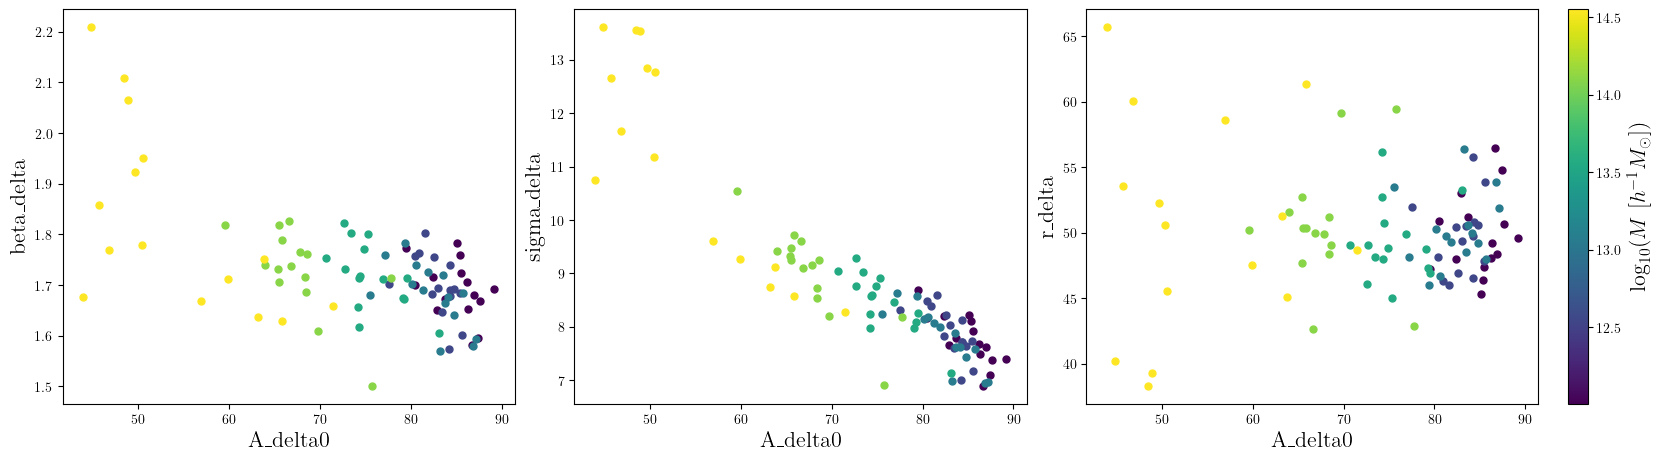

In [29]:
import h5py as h5
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy.stats import pearsonr

CACHE_PATH = '/spiffball/cosweeney/simulations/AbacusSummit_base/data/vel_mod_mass_dep.h5'

with h5.File(CACHE_PATH, 'r') as hdf:
    del_opts_full = hdf['del_opts_full'][:]   # (n_phases, n_mass, 4): A_delta0, r_delta, sigma_delta, beta_delta
    M_cens = hdf['M_cens'][:]

param_names = ['A_delta0', 'r_delta', 'sigma_delta', 'beta_delta']
n_phases, n_mass, _ = del_opts_full.shape

# amplitude-shape degeneracy candidates: does A_delta0 trade off against the shape params?
pairs = [('A_delta0', 'beta_delta'), ('A_delta0', 'sigma_delta'), ('A_delta0', 'r_delta')]

fig, ax = plt.subplots(1, len(pairs), figsize=(5.5 * len(pairs), 4.5), layout='constrained')
cmap = plt.cm.viridis
norm = mcolors.Normalize(vmin=np.log10(M_cens.min()), vmax=np.log10(M_cens.max()))

print(f'Pearson correlation across {n_phases} phases, per mass bin\n'
      f'(n={n_phases} per bin -- treat r as indicative, not tightly constrained)\n')

for pi, (p1, p2) in enumerate(pairs):
    i1, i2 = param_names.index(p1), param_names.index(p2)
    print(f'--- corr({p1}, {p2}) ---')
    for mi in range(n_mass):
        good = np.isfinite(del_opts_full[:, mi, i1]) & np.isfinite(del_opts_full[:, mi, i2])
        if good.sum() < 3:
            print(f'  mass bin {mi}: not enough finite phases ({good.sum()})')
            continue
        r, p = pearsonr(del_opts_full[good, mi, i1], del_opts_full[good, mi, i2])
        print(f'  mass bin {mi} (M={M_cens[mi]:.2e}): r = {r:+.2f}  (p = {p:.3f})')
        c = cmap(norm(np.log10(M_cens[mi])))
        ax[pi].scatter(del_opts_full[good, mi, i1], del_opts_full[good, mi, i2], color=c, s=25)
    ax[pi].set_xlabel(p1)
    ax[pi].set_ylabel(p2)
    print()

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
fig.colorbar(sm, ax=ax, location='right', pad=0.02, label=r'$\log_{10}(M\ [h^{-1}M_\odot])$')

fractional swing across mass bins:  A_delta0 = 0.42   Delta_peak(R=20) = 0.13


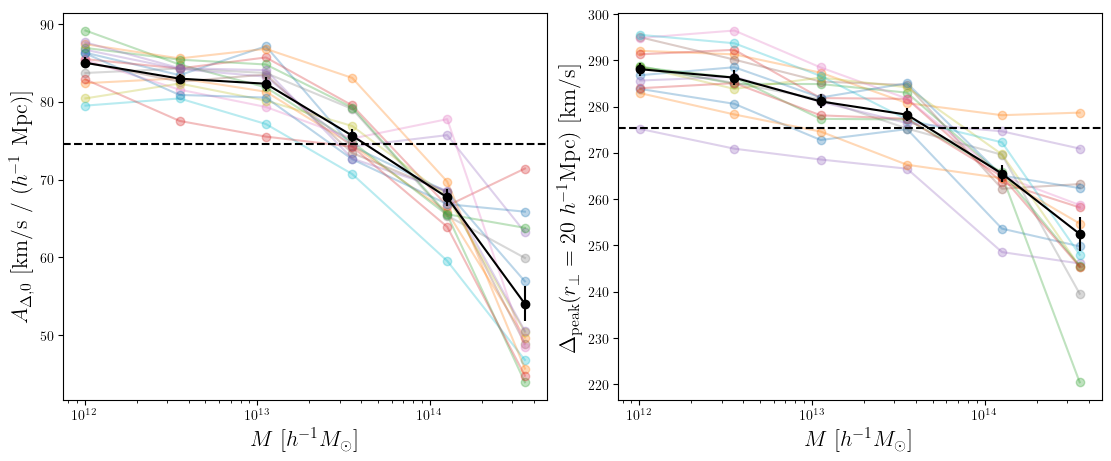

In [33]:
import h5py as h5
import numpy as np
import matplotlib.pyplot as plt

CACHE_PATH = '/spiffball/cosweeney/simulations/AbacusSummit_base/data/vel_mod_mass_dep.h5'

with h5.File(CACHE_PATH, 'r') as hdf:
    del_opts_full = hdf['del_opts_full'][:]  # (n_phases, n_mass, 4): A_delta0, r_delta, sigma_delta, beta_delta
    M_cens = hdf['M_cens'][:]

n_phases, n_mass, _ = del_opts_full.shape

def A_delta_mod(R, A_delta0, r_delta):
    return A_delta0 / (1 + (R / r_delta)**2)

def delta_mod_new(x, A, sigma_delta, beta_delta):
    return A * x / (1 + (x / sigma_delta)**beta_delta)

R_REF = 20.0  # h^-1 Mpc; well inside the flat core (r_delta ~ 45-65 across bins), so a stable reference

def peak_height(A_delta0, r_delta, sigma_delta, beta_delta, R_ref=R_REF):
    """Exact peak of Delta(x) at fixed r_perp=R_ref (closed form, beta_delta > 1 required)."""
    if beta_delta <= 1:
        return np.nan
    A = A_delta_mod(R_ref, A_delta0, r_delta)
    x_peak = sigma_delta * (1.0 / (beta_delta - 1.0))**(1.0 / beta_delta)
    return delta_mod_new(x_peak, A, sigma_delta, beta_delta)

peak_vals = np.array([[peak_height(*del_opts_full[si, mi]) for mi in range(n_mass)]
                       for si in range(n_phases)])

def jackknife_mean_err(arr):
    n = arr.shape[0]
    total = np.nansum(arr, axis=0)
    counts = np.sum(np.isfinite(arr), axis=0)
    mean_vals = total / counts
    if np.all(counts == n):
        loo_means = (total - arr) / (n - 1)
        err = np.sqrt((n - 1) / n * np.sum((loo_means - mean_vals)**2, axis=0))
    else:
        err = np.nanstd(arr, axis=0) / np.sqrt(counts)  # fallback if some (phase, mass) fits failed
    return mean_vals, err

A_mean, A_err = jackknife_mean_err(del_opts_full[:, :, 0])
peak_mean, peak_err = jackknife_mean_err(peak_vals)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), layout='constrained')
for si in range(n_phases):
    ax[0].plot(M_cens, del_opts_full[si, :, 0], marker='o', alpha=0.3)
    ax[1].plot(M_cens, peak_vals[si], marker='o', alpha=0.3)
ax[0].errorbar(M_cens, A_mean, yerr=A_err, marker='o', color='k')
ax[1].errorbar(M_cens, peak_mean, yerr=peak_err, marker='o', color='k')
ax[0].set_ylabel(r'$A_{\Delta,0}$ [km/s / ($h^{-1}$ Mpc)]')
ax[1].set_ylabel(rf'$\Delta_{{\rm peak}}(r_\perp={R_REF:.0f}\ h^{{-1}}{{\rm Mpc}})$ [km/s]')
ax[0].axhline(np.mean(A_mean), ls='--', c='k')
ax[1].axhline(np.mean(peak_mean), ls='--', c='k')
for a in ax:
    a.set_xlabel(r'$M\ [h^{-1}M_\odot]$')
    a.set_xscale('log')
    

frac_A = (A_mean.max() - A_mean.min()) / A_mean.mean()
frac_peak = (peak_mean.max() - peak_mean.min()) / peak_mean.mean()
print(f'fractional swing across mass bins:  A_delta0 = {frac_A:.2f}   Delta_peak(R={R_REF:.0f}) = {frac_peak:.2f}')

<>:28: SyntaxWarning: invalid escape sequence '\i'
<>:28: SyntaxWarning: invalid escape sequence '\i'
/tmp/ipykernel_758487/1959012693.py:28: SyntaxWarning: invalid escape sequence '\i'
  fig.suptitle(f'$M \in [{LOG_MASS_EDGES[K_SINGLE][0]}, {LOG_MASS_EDGES[K_SINGLE][1]}]$')


Text(0.5, 0.98, '$M \\in [13.5, 13.6]$')

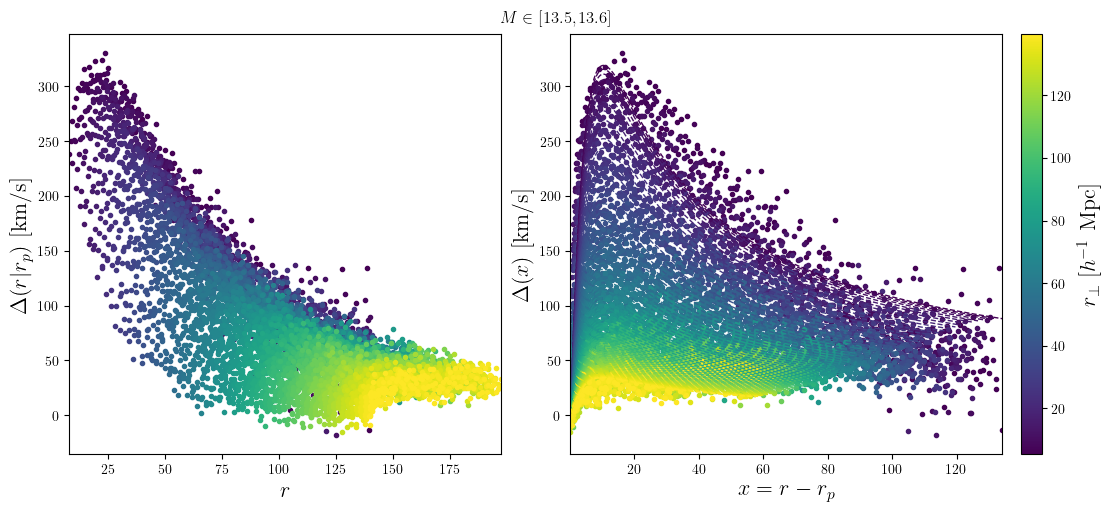

In [36]:
import matplotlib.colors as mcolors

norm_all = mcolors.Normalize(vmin=r_p_arr.min(), vmax=r_p_arr.max())

fig, ax = plt.subplots(1, 2, figsize=(11, 5), layout='constrained')
for j in range(0, len(r_p_arr), skip):
    m = Delta[j] > -1000
    c = cmap(norm_all(r_p_arr[j]))
    ax[0].plot(r3[j][m], Delta[j][m], 'o', ms=3, c=c)
    ax[1].plot(x[j][m], Delta[j][m], 'o', ms=3, c=c)

for j in range(0, len(r_p_arr), skip):
    m = Delta[j] > -1000
    xs = np.linspace(x[j][m].min(), x[j][m].max(), 500)
    A_here = A_delta_mod(r_p_arr[j], A_delta0, r_delta)
    ax[1].plot(xs, delta_mod_new(xs, A_here, sigma_delta, beta_delta),
               '--', c=cmap(norm_all(r_p_arr[j])), lw=1)

ax[0].set_xlabel(r'$r$'); ax[0].set_ylabel(r'$\Delta(r|r_p)$ [km/s]')
ax[1].set_xlabel(r'$x = r - r_p$'); ax[1].set_ylabel(r'$\Delta(x)$ [km/s]')
ax[0].margins(x=0)
ax[1].margins(x=0)
# ax[1].set_xscale('log')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm_all)
sm.set_array([])
fig.colorbar(sm, ax=ax, location='right', pad=0.02, label=r'$r_\perp$ [$h^{-1}$ Mpc]')
fig.suptitle(f'$M \in [{LOG_MASS_EDGES[K_SINGLE][0]}, {LOG_MASS_EDGES[K_SINGLE][1]}]$')

<>:47: SyntaxWarning: invalid escape sequence '\i'
<>:47: SyntaxWarning: invalid escape sequence '\i'
/tmp/ipykernel_656736/1180685663.py:47: SyntaxWarning: invalid escape sequence '\i'
  fig.suptitle(f'$M \in [{LOG_MASS_EDGES[K_SINGLE][0]}, {LOG_MASS_EDGES[K_SINGLE][1]}]$')


Text(0.5, 0.98, '$M \\in [13.5, 13.6]$')

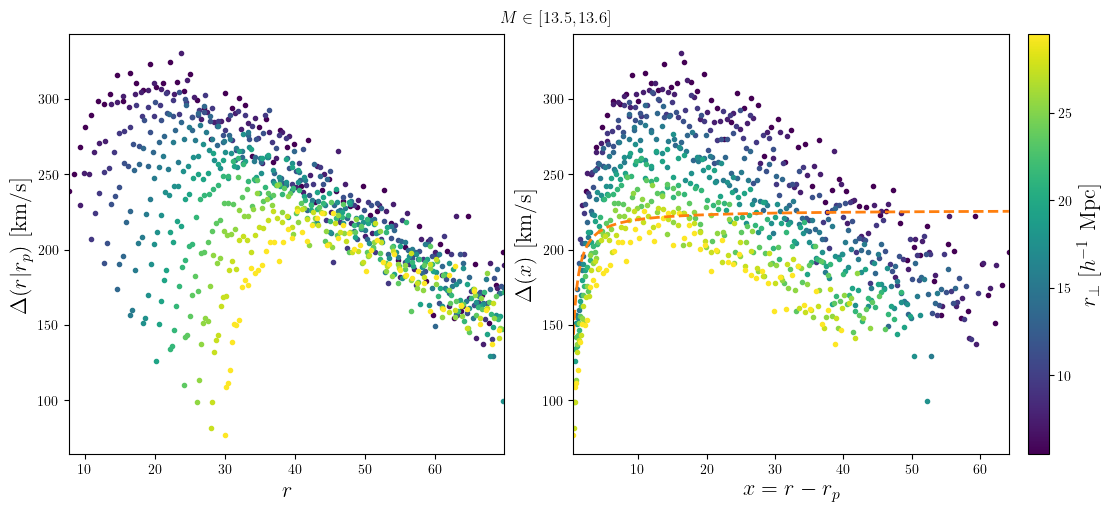

In [47]:
import matplotlib.colors as mcolors
from scipy.optimize import curve_fit

K_SINGLE = 3   # must match K_SINGLE in gather_paper_data.py
SIM_INDEX = 0  # which cached phase to show
RP_MAX = 30.0  # h^-1 Mpc

with h5.File('/spiffball/cosweeney/simulations/AbacusSummit_base/data/pdf_fits.h5', 'r') as hdf:
    ST_pars = hdf['ST_pars'][SIM_INDEX, K_SINGLE]   # (n_R, n_l, 3): xi, omega, alpha

# need <v_r|r> to form Delta = xi_st - mean_vr(r); pulled from the fig1 cache
# for the same mass bin (vr_r/vr_mean were saved there already)
with h5.File(CACHE, 'r') as hdf:
    vr_r = hdf['fig1'][f'mbin_{K_SINGLE}']['vr_r'][()]
    vr_mean = hdf['fig1'][f'mbin_{K_SINGLE}']['vr_mean'][()]
    del_opts_cached = hdf['sigma_delta']['del_opts'][SIM_INDEX, K_SINGLE]  # used as p0 only
good = np.isfinite(vr_mean)
mean_vr_interp = InterpolatedUnivariateSpline(vr_r[good], vr_mean[good], k=3, ext=3)

Delta = ST_pars[:, :, 0] - mean_vr_interp(r3) * r_l_2d / r3

# --- refit delta_mod to only the shown (r_p <= RP_MAX, r3 <= R_MAX) points ---
fit_mask = (Delta[idx_plot] > -1000) & (r3[idx_plot] <= R_MAX)
x_fit = x[idx_plot][fit_mask]
Delta_fit = Delta[idx_plot][fit_mask]
del_opts, _ = curve_fit(delta_mod, x_fit, Delta_fit, p0=del_opts_cached)

fig, ax = plt.subplots(1, 2, figsize=(11, 5), layout='constrained')
for j in idx_plot[::skip]:
    m = (Delta[j] > -1000) & (r3[j] <= R_MAX)
    c = cmap(norm(r_p_arr[j]))
    ax[0].plot(r3[j][m], Delta[j][m], 'o', ms=3, c=c)
    ax[1].plot(x[j][m], Delta[j][m], 'o', ms=3, c=c)

xs = np.linspace(x_fit.min(), x_fit.max(), 500)
ax[1].plot(xs, delta_mod(xs, *del_opts), 'C1--', lw=2)

ax[0].set_xlabel(r'$r$'); ax[0].set_ylabel(r'$\Delta(r|r_p)$ [km/s]')
ax[1].set_xlabel(r'$x = r - r_p$'); ax[1].set_ylabel(r'$\Delta(x)$ [km/s]')
#ax[1].set_xscale('log')
ax[0].margins(x=0)
ax[1].margins(x=0)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
fig.colorbar(sm, ax=ax, location='right', pad=0.02, label=r'$r_\perp$ [$h^{-1}$ Mpc]')
fig.suptitle(f'$M \in [{LOG_MASS_EDGES[K_SINGLE][0]}, {LOG_MASS_EDGES[K_SINGLE][1]}]$')


# fig.suptitle(f'Fig 4: mass bin {K_SINGLE}')
# fig.tight_layout()

## Fig 5 -- mild mass dependence, low vs high mass bin

Every velocity parameter (sigma0, A_piv, b, sigma_rho, A_delta, sigma_delta),
jackknifed over the cached fiducial phases, for just the two extreme mass
bins.

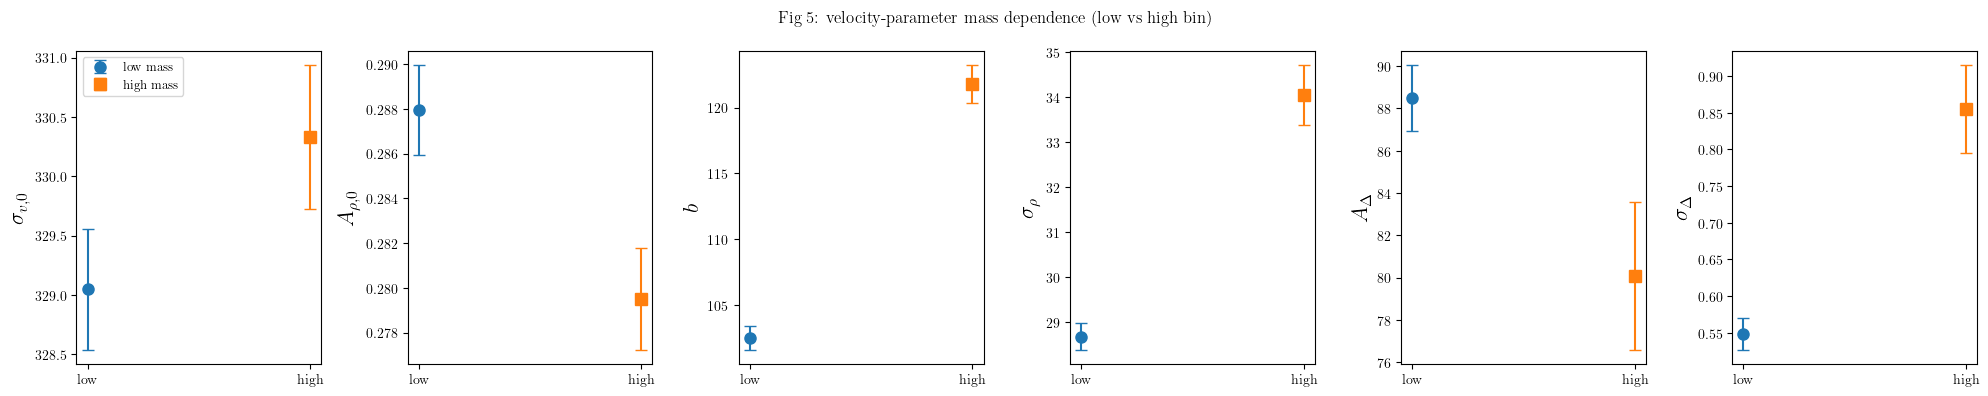

In [7]:
K_LOW, K_HIGH = 0, 5

def jackknife_mean_err(x):
    n = x.shape[0]
    total = x.sum(axis=0)
    mean_vals = total / n
    loo = (total - x) / (n - 1)
    err = np.sqrt((n - 1) / n * np.sum((loo - mean_vals) ** 2, axis=0))
    return mean_vals, err

with h5.File(CACHE, 'r') as hdf:
    sd = hdf['sigma_delta']
    params_all = np.concatenate([sd['sig_opts'][()], sd['del_opts'][()]], axis=-1)  # (n_sim, n_M, 6)

labels = [r'$\sigma_{v,0}$', r'$A_{\rho,0}$', r'$b$', r'$\sigma_\rho$',
          r'$A_\Delta$', r'$\sigma_\Delta$']

fig, ax = plt.subplots(1, 6, figsize=(20, 4))
for i in range(6):
    for k, label, marker in [(K_LOW, 'low mass', 'o'), (K_HIGH, 'high mass', 's')]:
        mean_val, err = jackknife_mean_err(params_all[:, k, i])
        ax[i].errorbar([0 if label == 'low mass' else 1], [mean_val], [err],
                        fmt=marker, ms=8, capsize=4, label=label if i == 0 else None)
    ax[i].set_xticks([0, 1]); ax[i].set_xticklabels(['low', 'high'])
    ax[i].set_ylabel(labels[i])
ax[0].legend(fontsize=9)
fig.suptitle('Fig 5: velocity-parameter mass dependence (low vs high bin)')
fig.tight_layout()


## Fig 6 -- cosmology dependence over the AbacusSummit emulator grid

Percent-difference around the best-fit line only (not the raw absolute-value
panel), scatter per grid sim with errorbars = the systematic from
low/high-mass-bin disagreement -- reproduced from `check_abacus_cosmo_runs.ipynb`
(the "spread about best-fit line" figure), restyled to match the paper.

IndexError: boolean index did not match indexed array along axis 0; size of axis is 52 but size of corresponding boolean axis is 51

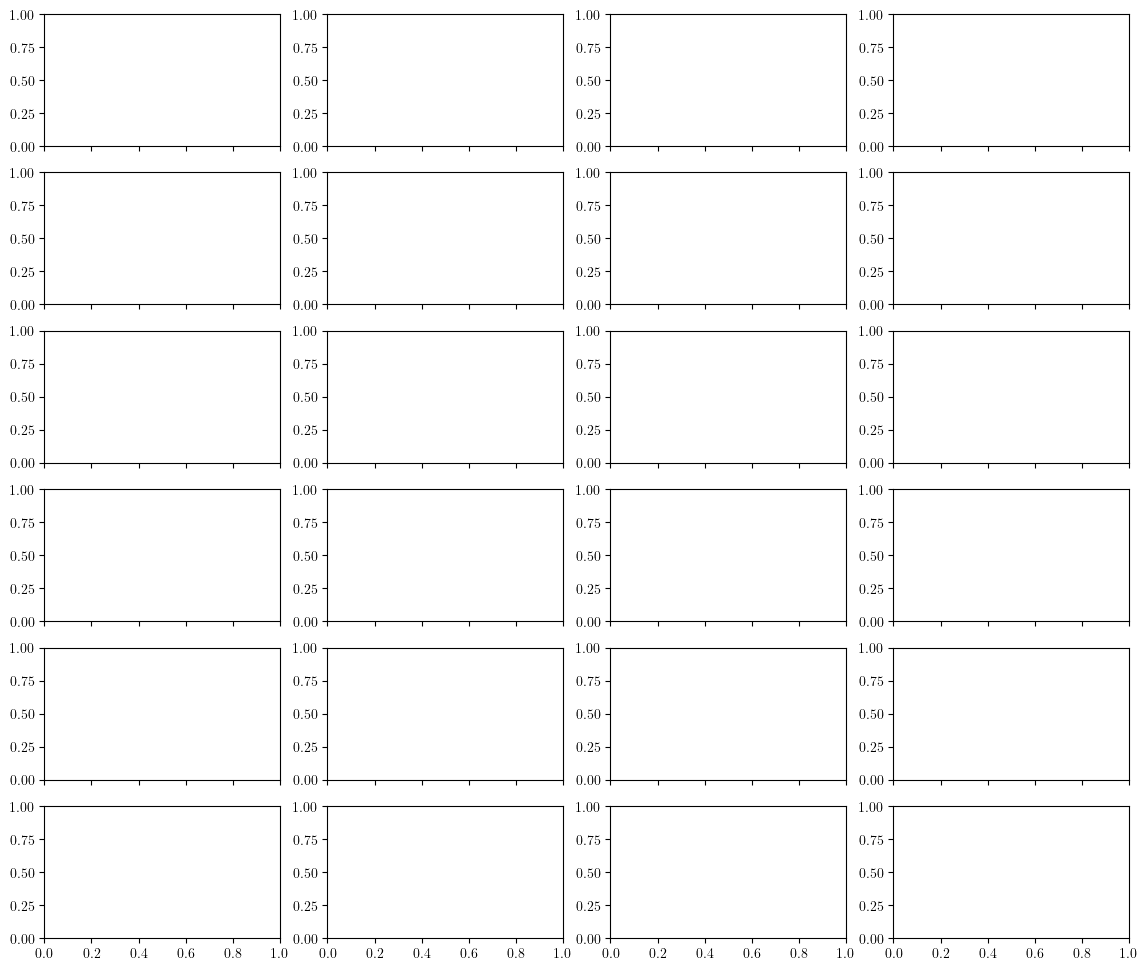

In [8]:
from scipy.stats import pearsonr

with h5.File(CACHE, 'r') as hdf:
    g6 = hdf['fig6']
    sig_opts_g = g6['sig_opts'][()]
    del_opts_g = g6['del_opts'][()]
    cosmo_arr = g6['cosmo_arr'][()]     # (n_sim, 4): omega_b, omega_cdm, sigma8_m, n_s
    cosmo_cols = list(g6.attrs['cosmo_cols'])

parameters = np.concatenate([sig_opts_g, del_opts_g], axis=-1)   # (n_sim, n_M=2, 6)
labels = [r'$\sigma_{v,0}$', r'$A_{\rho,0}$', r'$b$', r'$\sigma_\rho$',
          r'$A_\Delta$', r'$\sigma_\Delta$']
n_labels, n_cpars = len(labels), len(cosmo_cols)
n_M = parameters.shape[1]   # 2: low, high

RHO_MIN, P_MAX = 0.3, 0.05 / (n_labels * n_cpars)

fig, ax = plt.subplots(n_labels, n_cpars, figsize=(14, 12), sharex='col')
for i in range(n_labels):
    dependent_cols = []
    for j in range(n_cpars):
        good = np.isfinite(parameters[:, 0, i])
        rho, p = pearsonr(cosmo_arr[good, j], parameters[good, 0, i])
        if abs(rho) >= RHO_MIN and p < P_MAX:
            dependent_cols.append(j)

    if not dependent_cols:
        for j in range(n_cpars):
            ax[i, j].axis('off')
        continue

    X = np.column_stack([np.ones(len(cosmo_arr))] + [cosmo_arr[:, j] for j in dependent_cols])
    X_rep = np.repeat(X, n_M, axis=0)
    y = parameters[:, :, i].flatten()
    good = np.isfinite(y)
    beta, *_ = np.linalg.lstsq(X_rep[good], y[good], rcond=None)
    pred_simul = X @ beta

    beta_indiv = np.full((n_M, X.shape[1]), np.nan)
    for k in range(n_M):
        good_k = np.isfinite(parameters[:, k, i])
        beta_indiv[k], *_ = np.linalg.lstsq(X[good_k], parameters[good_k, k, i], rcond=None)
    pred_indiv = np.stack([X @ beta_indiv[k] for k in range(n_M)], axis=1)

    ratio = pred_simul[:, None] / parameters[:, :, i]
    sys_frac = (pred_indiv - pred_simul[:, None]) / parameters[:, :, i]

    for j in dependent_cols:
        for k in range(n_M):
            ax[i, j].errorbar(cosmo_arr[:, j], ratio[:, k], np.abs(sys_frac[:, k]),
                               fmt='o', ms=4, c=f'C{k}', capsize=2)
        ax[i, j].axhline(1, c='k', ls='--', lw=1)
    ax[i, dependent_cols[0]].set_ylabel(labels[i], fontsize=11)

for j in range(n_cpars):
    ax[-1, j].set_xlabel(cosmo_cols[j], fontsize=12)

fig.suptitle('Fig 6: percent-difference around best-fit cosmology-dependence line')
fig.tight_layout()


## Fig 7 -- P(v_los|r_p, r_los) vs calibrated model vs Gaussian

Fixed r_p, several r_los -- so the Hubble flow separates the bins, per your
suggestion. Uses the *calibrated* model (Pv_compact with the Fig 2-4 best-fit
params folded in), not an independent per-cell skew-t fit.

In [9]:
with h5.File(CACHE, 'r') as hdf:
    g7 = hdf['fig7']
    v_centers7 = g7['v_centers'][()]
    r_p_fixed = g7.attrs['r_p']
    cells = []
    for name in g7.keys():
        gc_ = g7[name]
        cells.append(dict(r_los=gc_.attrs['r_los'], n=gc_.attrs['n'],
                           mean=gc_.attrs['mean'], std=gc_.attrs['std'],
                           counts=gc_['counts'][()]))

# fold Fig 2-4's best-fit params into a single pars vector for Pv_compact:
# pars = [sigma0, A_rho0, sigma_rho, A_delta] (+ sigma_delta if fix_sig_Del=False)
pars_compact = np.array([sig_opts[0], sig_opts[1], sig_opts[3], del_opts[0]])

fig, axes = plt.subplots(1, len(cells), figsize=(5*len(cells), 4), sharey=True)
axes = np.atleast_1d(axes)
for ax_, cell in zip(axes, cells):
    dv = v_centers7[1] - v_centers7[0]
    density = cell['counts'] / (cell['counts'].sum() * dv)
    ax_.plot(v_centers7, density, drawstyle='steps-mid', c='k', label='data')

    v_model = Pv_compact(v_centers7, r_p_fixed, cell['r_los'], mean_vr_interp,
                          pars_compact, fix_sig_Del=True)
    ax_.plot(v_centers7, v_model, 'C1-', label='compact model')

    from scipy.stats import norm
    ax_.plot(v_centers7, norm.pdf(v_centers7, cell['mean'], cell['std']),
              'C2--', label='Gaussian')

    ax_.set_xlim(cell['mean'] - 6*cell['std'], cell['mean'] + 6*cell['std'])
    ax_.set_title(rf"$r_{{\rm los}}={cell['r_los']:.0f}$")
    ax_.set_xlabel(r'$v_{\rm los}$ [km/s]')
axes[0].set_ylabel(r'$P(v_{\rm los})$')
axes[0].legend(fontsize=9)
fig.suptitle(rf'Fig 7: $r_p={r_p_fixed:.0f}$ $h^{{-1}}$ Mpc, fiducial mass bin & cosmology')
fig.tight_layout()


KeyError: "Unable to synchronously open attribute (can't locate attribute: 'r_los')"